In [ ]:
%pip install -q --disable-pip-version-check optuna shap xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 18.3 MB/s eta 0:00:00


In [ ]:
import os
import random
import warnings
from datetime import datetime, timedelta, timezone
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn import metrics
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

import optuna
import shap


In [ ]:
SEED= 42
os.environ['PYTHONHASHSEED']= str(SEED)
random.seed(SEED)
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

sns.set_theme(
    style='whitegrid',
    context='notebook',
    palette='pastel',
)
plt.rcParams.update({
    'figure.figsize': (12,5),
    'figure.dpi':120,
    'axes.titleweight': 'bold',
})
print("Ambiente configurado com sucesso.")
print(f"Execução (UTC): {datetime.now(timezone.utc):%Y-%m-%d %H:%M}")
print(f"Seed global: {SEED}")
print(f"pandas: {pd.__version__} | scikit-learn: {__import__('sklearn').__version__}")

Ambiente configurado com sucesso.
Execução (UTC): 2026-07-28 11:17
Seed global: 42
pandas: 2.2.2 | scikit-learn: 1.6.1


In [ ]:
AIR_QUALITY_API = "https://air-quality-api.open-meteo.com/v1/air-quality"
WEATHER_API = "https://api.open-meteo.com/v1/forecast"
ARCHIVE_WEATHER_API = "https://archive-api.open-meteo.com/v1/archive"

HISTORICAL_DAYS= 90
FORECAST_HORIZON= 24
REQUEST_TIMEOUT= 45
MAX_RETRIES= 4

AIR_VARIABLES= [
    'pm2_5',
    'pm10',
    'nitrogen_dioxide',
    'ozone',
    'carbon_monoxide',
    'sulphur_dioxide',
]
WEATHER_VARIABLES= [
    'temperature_2m',
    'relative_humidity_2m',
    'precipitation',
    'surface_pressure',
    'cloud_cover',
    'wind_speed_10m',
    'wind_direction_10m',
]
CITIES = {
    "São Paulo": {
        "latitude": -23.5505,
        "longitude": -46.6333,
        "timezone": "America/Sao_Paulo",
    },
    "Rio de Janeiro": {
        "latitude": -22.9068,
        "longitude": -43.1729,
        "timezone": "America/Sao_Paulo",
    },
    "Brasília": {
        "latitude": -15.7939,
        "longitude": -47.8828,
        "timezone": "America/Sao_Paulo",
    },
    "Belo Horizonte": {
        "latitude": -19.9167,
        "longitude": -43.9345,
        "timezone": "America/Sao_Paulo",
    },
    "Salvador": {
        "latitude": -12.9777,
        "longitude": -38.5016,
        "timezone": "America/Bahia",
    },
    "Fortaleza": {
        "latitude": -3.7319,
        "longitude": -38.5267,
        "timezone": "America/Fortaleza",
    },
    "Recife": {
        "latitude": -8.0476,
        "longitude": -34.8768,
        "timezone": "America/Recife",
    },
    "Manaus": {
        "latitude": -3.1190,
        "longitude": -60.0217,
        "timezone": "America/Manaus",
    },
    "Curitiba": {
        "latitude": -25.4284,
        "longitude": -49.2733,
        "timezone": "America/Sao_Paulo",
    },
    "Porto Alegre": {
        "latitude": -30.0346,
        "longitude": -51.2177,
        "timezone": "America/Sao_Paulo",
    },
}

In [ ]:
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

API_FORECAST_DAYS= 3

def create_api_session(max_retries=MAX_RETRIES):
  '''
  CRIA UMA SESSÃO HTTP COM RETENTATIVAS E ESPERA PROGRESSIVA
  '''
  retry_strategy= Retry(
      total= max_retries,
      connect= max_retries,
      read= max_retries,
      backoff_factor= 1.5,
      status_forcelist=(429, 500, 502, 503, 504),
      allowed_methods= frozenset(['GET']),
      raise_on_status= False,
 )
  adapter= HTTPAdapter(max_retries= retry_strategy)
  session= requests.Session()
  session.mount("https://", adapter)
  return session

def request_hourly_data(session, url, params, source_name):
  '''
  CONSULTA UMA API E TRANSFORMA O BLOCO HORÁRIO EM DATAFRAME
  '''
  response= session.get(url, params= params, timeout= REQUEST_TIMEOUT)
  response.raise_for_status()

  json_response = response.json()
  hourly_data = json_response.get('hourly')

  if not hourly_data or 'time' not in hourly_data:
    reason= json_response.get('reason', 'bloco' 'hourly' 'ausente')
    raise ValueError(f'Resposta inválida de {source_name}: {reason}')
  dataframe= pd.DataFrame(hourly_data)
  dataframe['timestamp_utc'] = pd.to_datetime(
      dataframe.pop('time'),
      utc= True,
      errors= 'coerce',
  )
  dataframe= (
      dataframe
      .dropna(subset=['timestamp_utc'])
      .drop_duplicates(subset=['timestamp_utc'])
      .sort_values('timestamp_utc')
      .reset_index(drop=True)
  )
  return dataframe

def collect_city_data(session, city, config):
  '''
  COLETA E COMBINA POLUIÇÃO E METEOROGIA DE UMA CIDADE
  '''

  air_params= {
      'latitude': config['latitude'],
      'longitude': config['longitude'],
      'timezone': 'UTC',
      'past_days': HISTORICAL_DAYS,
      'forecast_days': API_FORECAST_DAYS,
      'hourly': ','.join(AIR_VARIABLES),
  }
  air_df= request_hourly_data(
      session,
      AIR_QUALITY_API,
      air_params,
      'OPEN-METEO AIR QUALITY',
  )

  # Parameters for Historical Weather API
  historical_weather_params= {
      'latitude': config['latitude'],
      'longitude': config['longitude'],
      'timezone': 'UTC',
      'start_date': (datetime.now(timezone.utc) - timedelta(days=HISTORICAL_DAYS)).strftime('%Y-%m-%d'),
      'end_date': (datetime.now(timezone.utc)).strftime('%Y-%m-%d'),
      'hourly': ','.join(WEATHER_VARIABLES),
  }
  historical_weather_df= request_hourly_data(
      session,
      ARCHIVE_WEATHER_API,
      historical_weather_params,
      'OPEN-METEO ARCHIVE WEATHER',
  )

  # Parameters for Forecast Weather API
  forecast_weather_params= {
      'latitude': config['latitude'],
      'longitude': config['longitude'],
      'timezone': 'UTC',
      'forecast_days': API_FORECAST_DAYS,
      'hourly': ','.join(WEATHER_VARIABLES),
  }
  forecast_weather_df= request_hourly_data(
      session,
      WEATHER_API,
      forecast_weather_params,
      'OPEN-METEO WEATHER FORECAST',
  )

  # Combine historical and forecast weather data
  weather_df = pd.concat([historical_weather_df, forecast_weather_df]).drop_duplicates(subset=['timestamp_utc']).sort_values('timestamp_utc').reset_index(drop=True)

  city_df= air_df.merge(
      weather_df,
      on= 'timestamp_utc',
      how= 'inner',
      validate= 'one_to_one',
  )
  city_df.insert(0, 'city', city)
  city_df['latitude']= config['latitude']
  city_df['longitude']= config['longitude']
  city_df['timezone']= config['timezone']

  return city_df

session= create_api_session()
collected_frames= []
collection_errors= {}

for city, config in CITIES.items():
  try:
    city_data= collect_city_data(session, city, config)
    collected_frames.append(city_data)
    print(f'{city}: {len(city_data):} registros')
  except(requests.RequestException, ValueError, KeyError) as error:
    collection_errors[city]= str(error)
    print(f'{city}: {error}')
session.close()

if not collected_frames:
  raise RuntimeError(
      '''
      NÃO FOI POSSIVEL COLETAR DADOS DE NENHUMA CIDA
      VERIFIQUE A CONEXÃO E TENTE EXECUTAR NOVAMENTE
      '''
  )
else:
  raw_df= (
      pd.concat(collected_frames, ignore_index=True)
      .sort_values(['city', 'timestamp_utc'])
      .reset_index(drop=True)
  )
  current_hour= pd.Timestamp.now(tz='UTC').floor('h')
  raw_df['period']= np.where(
      raw_df['timestamp_utc'] <= current_hour,
      'historical',
      'api_forecast',
  )

  print("\nResumo da coleta")
  print(f"Registros totais: {len(raw_df):,}")
  print(f"Cidades coletadas: {raw_df['city'].nunique()}")
  print(f"Período: {raw_df['timestamp_utc'].min()} até {raw_df['timestamp_utc'].max()}")
  print(f"Falhas: {len(collection_errors)}")

  display(raw_df.head())

São Paulo: 2232 registros
Rio de Janeiro: 2232 registros
Brasília: 2232 registros
Belo Horizonte: 2232 registros
Salvador: 2232 registros
Fortaleza: 2232 registros
Recife: 2232 registros
Manaus: 2232 registros
Curitiba: 2232 registros
Porto Alegre: 2232 registros

Resumo da coleta
Registros totais: 22,320
Cidades coletadas: 10
Período: 2026-04-29 00:00:00+00:00 até 2026-07-30 23:00:00+00:00
Falhas: 0


,city,pm2_5,pm10,nitrogen_dioxide,ozone,carbon_monoxide,sulphur_dioxide,timestamp_utc,temperature_2m,relative_humidity_2m,precipitation,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m,latitude,longitude,timezone,period
0,Belo Horizonte,10.70,10.90,20.60,34.00,197.00,4.20,2026-04-29 00:00:00+00:00,22.70,65,0.00,923.70,15,9.60,93,-19.92,-43.93,America/Sao_Paulo,historical
1,Belo Horizonte,10.80,11.00,20.60,32.00,216.00,4.20,2026-04-29 01:00:00+00:00,21.80,69,0.00,923.60,43,7.60,112,-19.92,-43.93,America/Sao_Paulo,historical
2,Belo Horizonte,10.90,11.10,20.50,29.00,245.00,4.10,2026-04-29 02:00:00+00:00,21.20,70,0.00,923.70,13,7.20,125,-19.92,-43.93,America/Sao_Paulo,historical
3,Belo Horizonte,11.00,11.20,20.10,27.00,258.00,4.10,2026-04-29 03:00:00+00:00,20.70,70,0.00,923.40,2,8.50,114,-19.92,-43.93,America/Sao_Paulo,historical
4,Belo Horizonte,10.90,11.10,19.00,26.00,236.00,4.00,2026-04-29 04:00:00+00:00,20.00,70,0.00,922.90,1,9.00,116,-19.92,-43.93,America/Sao_Paulo,historical


In [ ]:
if 'raw_df' not in globals() or raw_df.empty:
  raise RuntimeError('execute primeiro a célula de colota de dados')
data_df= raw_df.copy()

numeric_columns= [
    column
    for column in AIR_VARIABLES + WEATHER_VARIABLES
    if column in data_df.columns
]

data_df[numeric_columns] = data_df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce",
)

data_df[numeric_columns]= data_df[numeric_columns].replace(
    [np.inf, -np.inf],
    np.nan,
)

duplicate_count= data_df.duplicated(
    subset=['city', 'timestamp_utc']
).sum()

missing_report= (
    data_df[numeric_columns]
    .isna()
    .agg(['sum', 'mean'])
    .T
    .rename(columns={'sum': 'missing_count', 'mean': 'missing_rate'})
)
missing_report['missing_count']= missing_report['missing_count'].astype(int)
missing_report['missing_percent']= missing_report['missing_rate'] * 100
missing_report= (
    missing_report
    .drop(columns='missing_rate')
    .sort_values('missing_percent', ascending=False)
)

time_gaps= (
    data_df
    .sort_values(['city', 'timestamp_utc'])
    .groupby('city')['timestamp_utc']
    .diff()
    .dt.total_seconds()
    .div(3600)
)

irregular_intervals= int(
    ((time_gaps.notna()) & (~np.isclose(time_gaps, 1))).sum()
)
city_quality = (
    data_df
    .groupby("city", observed=True)
    .agg(
        records=("timestamp_utc", "size"),
        start=("timestamp_utc", "min"),
        end=("timestamp_utc", "max"),
        pm25_missing=("pm2_5", lambda series: series.isna().mean() * 100),
        pm25_mean=("pm2_5", "mean"),
        pm25_median=("pm2_5", "median"),
        pm25_max=("pm2_5", "max"),
    )
    .reset_index()
    .sort_values("pm25_mean", ascending=False)
)

print("AUDITORIA GERAL")
print(f"Dimensão: {data_df.shape[0]:,} linhas x {data_df.shape[1]} colunas")
print(f"Duplicidades cidade-horário: {duplicate_count:,}")
print(f"Intervalos temporais irregulares: {irregular_intervals:,}")
print(f"Ausência geral nas variáveis: {data_df[numeric_columns].isna().mean().mean():.2%}")

print("\nQUALIDADE POR CIDADE")
display(
    city_quality.style.format({
        "pm25_missing": "{:.2f}%",
        "pm25_mean": "{:.2f}",
        "pm25_median": "{:.2f}",
        "pm25_max": "{:.2f}",
    })
)

print("\nVALORES AUSENTES POR VARIÁVEL")
display(
    missing_report.style.format({
        "missing_percent": "{:.2f}%"
    })
)

missing_plot = (
    missing_report
    .query("missing_count > 0")
    .reset_index()
    .rename(columns={"index": "variable"})
)

if not missing_plot.empty:
    fig = px.bar(
        missing_plot,
        x="missing_percent",
        y="variable",
        orientation="h",
        text_auto=".2f",
        title="Percentual de valores ausentes por variável",
        labels={
            "missing_percent": "Valores ausentes (%)",
            "variable": "Variável",
        },
        color="missing_percent",
        color_continuous_scale="Reds",
    )

    fig.update_layout(
        template="plotly_white",
        height=max(400, 35 * len(missing_plot)),
        coloraxis_showscale=False,
        yaxis={"categoryorder": "total ascending"},
    )
    fig.show()
else:
    print("Nenhum valor ausente foi identificado nas variáveis numéricas.")

AUDITORIA GERAL
Dimensão: 22,320 linhas x 19 colunas
Duplicidades cidade-horário: 0
Intervalos temporais irregulares: 0
Ausência geral nas variáveis: 0.00%

QUALIDADE POR CIDADE


,city,records,start,end,pm25_missing,pm25_mean,pm25_median,pm25_max
9,São Paulo,2232,2026-04-29 00:00:00+00:00,2026-07-30 23:00:00+00:00,0.00%,20.84,14.45,129.50
7,Rio de Janeiro,2232,2026-04-29 00:00:00+00:00,2026-07-30 23:00:00+00:00,0.00%,19.52,16.90,61.20
8,Salvador,2232,2026-04-29 00:00:00+00:00,2026-07-30 23:00:00+00:00,0.00%,11.15,9.80,49.20
0,Belo Horizonte,2232,2026-04-29 00:00:00+00:00,2026-07-30 23:00:00+00:00,0.00%,11.06,9.30,47.10
5,Porto Alegre,2232,2026-04-29 00:00:00+00:00,2026-07-30 23:00:00+00:00,0.00%,10.95,8.60,53.20
2,Curitiba,2232,2026-04-29 00:00:00+00:00,2026-07-30 23:00:00+00:00,0.00%,9.25,7.00,43.10
4,Manaus,2232,2026-04-29 00:00:00+00:00,2026-07-30 23:00:00+00:00,0.00%,8.63,8.00,27.70
6,Recife,2232,2026-04-29 00:00:00+00:00,2026-07-30 23:00:00+00:00,0.00%,7.52,7.10,15.70
3,Fortaleza,2232,2026-04-29 00:00:00+00:00,2026-07-30 23:00:00+00:00,0.00%,5.81,5.50,14.70
1,Brasília,2232,2026-04-29 00:00:00+00:00,2026-07-30 23:00:00+00:00,0.00%,5.67,4.30,39.60



VALORES AUSENTES POR VARIÁVEL


,missing_count,missing_percent
pm2_5,0,0.00%
pm10,0,0.00%
nitrogen_dioxide,0,0.00%
ozone,0,0.00%
carbon_monoxide,0,0.00%
sulphur_dioxide,0,0.00%
temperature_2m,0,0.00%
relative_humidity_2m,0,0.00%
precipitation,0,0.00%
surface_pressure,0,0.00%


Nenhum valor ausente foi identificado nas variáveis numéricas.


In [ ]:
RISK_THRESHOLD= {
    'baixo': 15,
    'medio': 35,
}

if "data_df" not in globals() or data_df.empty:
    raise RuntimeError("Execute primeiro as células de coleta e auditoria.")

clean_df = (
    data_df.copy()
    .sort_values(["city", "timestamp_utc"])
    .drop_duplicates(subset=["city", "timestamp_utc"], keep="last")
    .reset_index(drop=True)
)

physical_bounds = {
    "pm2_5": (0, None),
    "pm10": (0, None),
    "nitrogen_dioxide": (0, None),
    "ozone": (0, None),
    "carbon_monoxide": (0, None),
    "sulphur_dioxide": (0, None),
    "temperature_2m": (-40, 60),
    "relative_humidity_2m": (0, 100),
    "precipitation": (0, None),
    "surface_pressure": (750, 1100),
    "cloud_cover": (0, 100),
    "wind_speed_10m": (0, 250),
    "wind_direction_10m": (0, 360),
}

invalid_counts = {}

for column, (lower_bound, upper_bound) in physical_bounds.items():
    if column not in clean_df.columns:
        continue

    invalid_mask = clean_df[column] < lower_bound

    if upper_bound is not None:
        invalid_mask |= clean_df[column] > upper_bound

    invalid_counts[column] = int(invalid_mask.sum())
    clean_df.loc[invalid_mask, column] = np.nan

causal_fill_columns = [
    column
    for column in numeric_columns
    if column != "pm2_5"
]

missing_before = int(clean_df[causal_fill_columns].isna().sum().sum())

clean_df[causal_fill_columns] = (
    clean_df
    .groupby("city", observed=True)[causal_fill_columns]
    .ffill(limit=3)
)

missing_after = int(clean_df[causal_fill_columns].isna().sum().sum())

#
past_pm25 = clean_df.groupby("city", observed=True)["pm2_5"].shift(1)

rolling_median = (
    past_pm25
    .groupby(clean_df["city"], observed=True)
    .transform(
        lambda series: series.rolling(
            window=168,
            min_periods=48,
        ).median()
    )
)

rolling_mad = (
    past_pm25
    .groupby(clean_df["city"], observed=True)
    .transform(
        lambda series: series.rolling(
            window=168,
            min_periods=48,
        ).apply(
            lambda values: np.median(
                np.abs(values - np.median(values))
            ),
            raw=True,
        )
    )
)

clean_df["pm25_robust_z"] = (
    0.6745
    * (clean_df["pm2_5"] - rolling_median).abs()
    / rolling_mad.replace(0, np.nan)
)

clean_df["pm25_extreme_flag"] = (
    clean_df["pm25_robust_z"] > 5
).astype("int8")

clean_df["current_risk"] = pd.cut(
    clean_df["pm2_5"],
    bins=[-np.inf, RISK_THRESHOLD["baixo"], RISK_THRESHOLD["medio"], np.inf],
    labels=["baixo", "medio", "alto"],
    include_lowest=True,
)

cleaning_summary = pd.DataFrame({
    "variavel": list(invalid_counts),
    "valores_invalidos_corrigidos": list(invalid_counts.values()),
}).sort_values("valores_invalidos_corrigidos", ascending=False)

print("RESUMO DA LIMPEZA")
print(f"Registros após remover duplicidades: {len(clean_df):,}")
print(f"Lacunas nos preditores antes do ffill: {missing_before:,}")
print(f"Lacunas nos preditores depois do ffill: {missing_after:,}")
print(f"Picos robustos de PM2.5 preservados: {clean_df['pm25_extreme_flag'].sum():,}")

display(cleaning_summary)

risk_distribution = (
    clean_df.loc[clean_df["period"] == "historical", "current_risk"]
    .value_counts(normalize=True, sort=False)
    .mul(100)
    .rename("percentual")
    .reset_index()
)

display(
    risk_distribution.style.format({
        "percentual": "{:.2f}%"
    })
)


RESUMO DA LIMPEZA
Registros após remover duplicidades: 22,320
Lacunas nos preditores antes do ffill: 0
Lacunas nos preditores depois do ffill: 0
Picos robustos de PM2.5 preservados: 437


,variavel,valores_invalidos_corrigidos
0,pm2_5,0
1,pm10,0
2,nitrogen_dioxide,0
3,ozone,0
4,carbon_monoxide,0
5,sulphur_dioxide,0
6,temperature_2m,0
7,relative_humidity_2m,0
8,precipitation,0
9,surface_pressure,0


,current_risk,percentual
0,baixo,80.87%
1,medio,16.00%
2,alto,3.13%


In [ ]:
eda_df= (
    clean_df.loc[
        (clean_df['period']== 'historical')
        & clean_df['pm2_5'].notna()
    ]
    .copy()
    .reset_index(drop=True)
)
if eda_df.empty:
  raise RuntimeError('não existem observações históricas válidas para o EDA')

eda_df['local_hour']= pd.Series(index=eda_df.index, dtype='int16')
eda_df['local_date']= pd.NaT

for timezone_name, indices in eda_df.groupby('timezone').groups.items():
  local_timestamp = (
      eda_df.loc[indices, 'timestamp_utc']
      .dt.tz_convert(timezone_name)
  )
  eda_df.loc[indices, 'local_hour']= local_timestamp.dt.hour.to_numpy()
  eda_df.loc[indices, 'local_date']= (
      local_timestamp
      .dt.tz_localize(None)
      .dt.floor('D')
      .to_numpy()
  )
eda_df['local_hour']= eda_df['local_hour'].astype(int)
daily_pm25= (
    eda_df
    .groupby(['city', 'local_date'], observed=True, as_index=False)
    .agg(
        pm2_5_mean= ('pm2_5', 'mean'),
        pm2_5_max= ('pm2_5', 'max'),
    )
    )
trend_fig= px.line(
    daily_pm25,
    x= 'local_date',
    y= 'pm2_5_mean',
    color= 'city',
    title= 'evolução da concentração média diária de PM2.5',
    labels= {
        'local_date': 'Data Local',
        'pm2_5_mean': 'PM2.5 Médio',
        'city': 'Cidade',
    },
    color_discrete_sequence= px.colors.qualitative.Bold,
)
trend_fig.add_hline(
    y= 15,
    line_dash= 'dash',
    line_color= '#F59E0B',
    annotation_text= 'limite baixo: 15',
    annotation_position= 'top left',
)
trend_fig.add_hline(
    y= 35,
    line_dash= 'dash',
    line_color= '#DC2626',
    annotation_text= 'risco alto: 35',
    annotation_position= 'top right',
)
trend_fig.update_layout(
    template= 'plotly_white',
    height= 560,
    hovermode= 'x unified',
    legend_title_text= 'cidade',
)
trend_fig.show()

city_order= (
  eda_df
  .groupby('city', observed=True)['pm2_5']
  .median()
  .sort_values(ascending=False)
  .index
  .tolist()
)

box_fig= px.box(
    eda_df,
    x= 'city',
    y= 'pm2_5',
    color= 'city',
    category_orders={'city': city_order},
    points= False,
    title='distribuição horária de PM2.5 por cidade',
    labels={
        'city': 'cidade',
        'pm2_5': 'PM2.5'
    },
    color_discrete_sequence=px.colors.qualitative.Bold,
)
box_fig.add_hline(
    y=35,
    line_dash='dot',
    line_color='#DC2626',
    annotation_text='inicio do risco alto',
)
box_fig.update_layout(
    template='plotly_white',
    height=520,
    showlegend= False,
    xaxis_tickangle= 35,
)
box_fig.show()

hourly_profile= (
    eda_df
    .groupby(['city', 'local_hour'], observed=True)['pm2_5']
    .mean()
    .unstack()
    .reindex(index=city_order, columns=range(24))
)
heatmap_fig= go.Figure(
    data= go.Heatmap(
        z= hourly_profile.values,
        x= hourly_profile.columns,
        y= hourly_profile.index,
        colorscale= 'YlOrRd',
        colorbar={"title": "PM2.5<br>µg/m³"},
        hovertemplate=(
            "Cidade: %{y}<br>"
            "Hora local: %{x}:00<br>"
            "PM2.5 médio: %{z:.2f} µg/m³"
            "<extra></extra>"
        ),

    )
)
heatmap_fig.update_layout(
    title= 'perfil medio de pm2 por hora local',
    template='plotly_white',
    height=500,
    xaxis_title='hora local',
    yaxis_title='cidade'
)
heatmap_fig.show()

display(
    eda_df.groupby('city', observed=True)['pm2_5']
    .agg(['count','mean', 'median', 'std', 'min', 'max'])
    .sort_values('mean', ascending=False)
    .style.format('{:.2f}')
)


,count,mean,median,std,min,max
city,,,,,,
São Paulo,2172.00,20.95,14.50,17.72,2.20,129.50
Rio de Janeiro,2172.00,19.33,16.70,9.96,4.70,61.20
Salvador,2172.00,11.12,9.70,5.94,3.30,49.20
Porto Alegre,2172.00,11.03,8.60,8.23,0.70,53.20
Belo Horizonte,2172.00,10.99,9.30,6.49,1.60,47.10
Curitiba,2172.00,9.31,7.05,7.24,0.10,43.10
Manaus,2172.00,8.66,8.00,4.47,0.60,27.70
Recife,2172.00,7.46,7.00,2.73,1.50,15.70
Fortaleza,2172.00,5.75,5.40,2.56,0.10,14.70


In [ ]:
historical_df= (
    clean_df.loc[clean_df['period'] == 'historical']
    .copy()
    .sort_values(['city', 'timestamp_utc'])
    .reset_index(drop=True)
)
if historical_df.empty:
  raise RuntimeError('não há dados históricos disponíveis')
historical_df['local_datetime']= pd.NaT

for timezone_name, indices in historical_df.groupby('timezone').groups.items():
  local_timestamp=(
      historical_df.loc[indices, 'timestamp_utc']
      .dt.tz_convert(timezone_name)
      .dt.tz_localize(None)
  )
  historical_df.loc[indices, 'local_datetime']= local_timestamp.to_numpy()

historical_df['hour']= historical_df['local_datetime'].dt.hour
historical_df['day_of_week']= historical_df['local_datetime'].dt.dayofweek
historical_df['month']= historical_df['local_datetime'].dt.month
historical_df['day_of_year']= historical_df['local_datetime'].dt.dayofyear
historical_df['is_weekend']= (
    historical_df['day_of_week'] >= 5
).astype('int8')

historical_df['hour_sin']= np.sin(2 * np.pi * historical_df['hour'] / 24)
historical_df['hour_cos']= np.cos(2 * np.pi * historical_df['hour'] / 24)
historical_df['week_sin']= np.sin(2 * np.pi * historical_df['day_of_week'] / 7)
historical_df['week_cos']= np.sin(2 * np.pi * historical_df['day_of_week'] / 7)
historical_df['year_sin']= np.sin(2 * np.pi * historical_df['day_of_year'] / 365.25 )
historical_df['year_cos']= np.cos(2 * np.pi * historical_df['day_of_year'] / 365.25 )

wind_radians= np.deg2rad(historical_df['wind_direction_10m'])
historical_df['wind_direction_sin']= np.sin(wind_radians)
historical_df['wind_direction_cos']= np.cos(wind_radians)
historical_df['pm2_5_current']= historical_df['pm2_5']

pm25_group= historical_df.groupby(
    'city',
    observed= True,
)['pm2_5']

lag_hours= [1, 3, 6, 12, 24, 48, 72]

for lag in lag_hours:
  historical_df[f'pm2_5_lag_{lag}h']= pm25_group.shift(lag)
past_pm25= pm25_group.shift(1)
rolling_windows= [3, 6, 12, 24, 72, 168]

for window in rolling_windows:
  grouped_past= past_pm25.groupby(
      historical_df['city'],
      observed= True,
  )
  historical_df[f'pm2_5_roll_mean_{window}h']= (
      grouped_past.transform(
          lambda series: series.rolling(
              window,
              min_periods=max(2, window // 2),
       ).mean()
      )
  )
  historical_df[f'pm2_5_roll_std_{window}h']= (
      grouped_past.transform(
          lambda series: series.rolling(
              window,
              min_periods= max(2, window // 2),
         ).std()
      )
  )
for column in ['pm2_5', 'temperature_2m', 'relative_humidity_2m', 'wind_speed_10m']:
  grouped_column= historical_df.groupby(
      'city',
      observed= True,
    )[column]
  historical_df[f'{column}_change_3h']= (
        historical_df[column] - grouped_column.shift(3)
    )
  historical_df[f'{column}_change_24h']= (
        historical_df[column] - grouped_column.shift(24)
    )
historical_df['pm25_pm10_ration']= (
    historical_df['pm2_5']
    / historical_df['pm10'].replace(0, np.nan)
)

feature_origin_df= historical_df.loc[
    historical_df['pm2_5_lag_72h'].notna()
].copy()
horizon_frames= []

for horizon in range(1, FORECAST_HORIZON + 1):
  horizon_df = feature_origin_df.copy()
  grouped_target= historical_df.groupby(
      'city',
      observed=True,
  )
  horizon_df['target_pm2_5']= grouped_target['pm2_5'].shift(
      -horizon
  ).loc[horizon_df.index]
  horizon_df['target_timestamp_utc']= (
      grouped_target['timestamp_utc'].shift(-horizon).loc[horizon_df.index]
  )
  expected_timestamp= (
      horizon_df['timestamp_utc']
      + pd.to_timedelta(horizon, unit='h')
  )
  horizon_df= horizon_df.loc[
      horizon_df['target_timestamp_utc'].eq(expected_timestamp)
      & horizon_df['target_pm2_5'].notna()
      ].copy()
  horizon_df['forecast_horizon']= horizon

  target_local_datetime= (
      horizon_df['local_datetime']
      + pd.to_timedelta(horizon, unit='h')
  )
  target_hour= target_local_datetime.dt.hour
  target_weekday= target_local_datetime.dt.dayofweek

  horizon_df['target_hour_sin']= np.sin(
      2 * np.pi * target_hour / 24
  )
  horizon_df['target_hour_cos']= np.cos(
      2 * np.pi * target_hour / 24
  )
  horizon_df['target_weekday_sin']= np.sin(
      2 * np.pi * target_weekday / 7
  )
  horizon_df['target_weekday_cos']= np.cos(
      2 * np.pi * target_weekday / 7
  )

  horizon_df['target_risk']= pd.cut(
      horizon_df['target_pm2_5'],
      bins=[
          -np.inf,
          RISK_THRESHOLD['baixo'],
          RISK_THRESHOLD['medio'],
          np.inf,
      ],
      labels=['baixo', 'medio', 'alto'],
      include_lowest=True
  )
  horizon_frames.append(horizon_df)

supervised_df= (
    pd.concat(horizon_frames, ignore_index=True)
    .sort_values(['timestamp_utc', 'city', 'forecast_horizon'])
    .reset_index(drop=True)
)
categorical_features= ['city']
excluded_numetic= {
    'pm2_5',
    'wind_direction_10m',
    'pm25_robust_z',
    'pm25_extreme_flag',
}
numeric_features= [
    column
    for column in supervised_df.select_dtypes(include=np.number).columns
    if column not in excluded_numetic
    and not column.startswith('target_')
]
numeric_features += [
    'target_hour_sin',
    'target_hour_cos',
    'target_weekday_sin',
    'target_weekday_cos',
]
numeric_features= list(dict.fromkeys(numeric_features))
model_features= categorical_features + numeric_features

print("CONJUNTO SUPERVISIONADO")
print(f"Registros: {len(supervised_df):,}")
print(f"Atributos do modelo: {len(model_features)}")
print(f"Horizontes: {supervised_df['forecast_horizon'].min()}h a "
      f"{supervised_df['forecast_horizon'].max()}h")
print(f"Cidades: {supervised_df['city'].nunique()}")
print(f"Alvo médio: {supervised_df['target_pm2_5'].mean():.2f} µg/m³")

display(
    supervised_df["target_risk"]
    .value_counts(normalize=True, sort=False)
    .mul(100)
    .rename("percentual")
    .to_frame()
    .style.format("{:.2f}%")
)


CONJUNTO SUPERVISIONADO
Registros: 501,000
Atributos do modelo: 61
Horizontes: 1h a 24h
Cidades: 10
Alvo médio: 11.05 µg/m³


,percentual
target_risk,
baixo,80.86%
medio,15.99%
alto,3.15%


In [ ]:
if 'supervised_df' not in globals() or supervised_df.empty:
  raise RuntimeError('execute primeiro a celula de feature engineering')
HOLDOUT_DAYS= 14
CV_SPLITS= 4
CV_TEST_HOUR= 7 * 24
CV_GAP_HOURS= FORECAST_HORIZON
RISK_LABELS= ['baixo', 'medio', 'alto']

origin_times= pd.DatetimeIndex(
    supervised_df['timestamp_utc']
    .drop_duplicates()
    .sort_values()
)
minimum_required_hours= (
    HOLDOUT_DAYS * 24
    + CV_SPLITS * CV_TEST_HOUR
    + CV_SPLITS * CV_GAP_HOURS
)
if len(origin_times) <= minimum_required_hours:
  raise RuntimeError(
      'historico insuficiente para a configuração de validação',
      f'necessario: mais de {minimum_required_hours} horas',
      f'disponivel: {len(origin_times)}'
  )
holdout_start= origin_times[-HOLDOUT_DAYS * 24]
development_df= (
    supervised_df.loc[
        supervised_df['target_timestamp_utc'] < holdout_start
    ]
    .copy()
    .reset_index(drop=True)
)
test_df= (
    supervised_df.loc[
        supervised_df['timestamp_utc'] >= holdout_start
    ]
    .copy()
    .reset_index(drop=True)
)
development_origins= pd.DatetimeIndex(
    development_df['timestamp_utc']
    .drop_duplicates()
    .sort_values()
)
time_splitter= TimeSeriesSplit(
    n_splits= CV_SPLITS,
    test_size= CV_TEST_HOUR,
    gap= CV_GAP_HOURS,
)
cv_folds= []

for fold_number, (train_time_idx, validation_time_idx) in enumerate(
    time_splitter.split(development_origins),
    start= 1,
):
  train_times= development_origins[train_time_idx]
  validation_times= development_origins[validation_time_idx]
  train_rows= np.flatnonzero(
      development_df['timestamp_utc'].isin(train_times).to_numpy()
  )
  validation_rows= np.flatnonzero(
      development_df['timestamp_utc'].isin(validation_times).to_numpy()
  )

  cv_folds.append((train_rows, validation_rows))

  print(
      f"Fold {fold_number}: "
      f"treino até {train_times.max():%Y-%m-%d %H:%M} UTC | "
      f"validação de {validation_times.min():%Y-%m-%d %H:%M} "
      f"até {validation_times.max():%Y-%m-%d %H:%M} UTC"
  )
def pm25_to_risk(values):
    """Converte concentrações de PM2.5 nas três classes de risco."""
    values = np.asarray(values, dtype=float)

    return np.select(
        [
            values <= RISK_THRESHOLD["baixo"],
            values <= RISK_THRESHOLD["medio"],
        ],
        ["baixo", "medio"],
        default="alto",
    )


def calculate_regression_metrics(y_true, y_pred):
    """Calcula métricas principais de regressão."""
    return {
        "MAE": metrics.mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(metrics.mean_squared_error(y_true, y_pred)),
        "R2": metrics.r2_score(y_true, y_pred),
    }


if development_df.empty or test_df.empty:
    raise RuntimeError("A divisão temporal produziu um conjunto vazio.")

# Baseline: assume que o PM2.5 permanecerá igual ao valor atual.
baseline_predictions = test_df["pm2_5_current"].clip(lower=0)
baseline_true = test_df["target_pm2_5"]

baseline_metrics = calculate_regression_metrics(
    baseline_true,
    baseline_predictions,
)

baseline_true_risk = pm25_to_risk(baseline_true)
baseline_predicted_risk = pm25_to_risk(baseline_predictions)

baseline_metrics["F1_weighted"] = metrics.f1_score(
    baseline_true_risk,
    baseline_predicted_risk,
    labels=RISK_LABELS,
    average="weighted",
    zero_division=0,
)

baseline_by_horizon = (
    test_df
    .assign(baseline_prediction=baseline_predictions)
    .groupby("forecast_horizon", observed=True)
    .apply(
        lambda group: pd.Series(
            calculate_regression_metrics(
                group["target_pm2_5"],
                group["baseline_prediction"],
            )
        ),
        include_groups=False,
    )
    .reset_index()
)

print("\nDIVISÃO DOS DADOS")
print(f"Desenvolvimento: {len(development_df):,} registros")
print(f"Teste final: {len(test_df):,} registros")
print(f"Início do holdout: {holdout_start}")
print(f"Intervalo de segurança dos folds: {CV_GAP_HOURS} horas")

print("\nRESULTADO DO BASELINE")
display(
    pd.DataFrame([baseline_metrics], index=["Persistência"])
    .style.format("{:.4f}")
)

baseline_fig = px.line(
    baseline_by_horizon,
    x="forecast_horizon",
    y=["MAE", "RMSE"],
    markers=True,
    title="Erro do baseline por horizonte de previsão",
    labels={
        "forecast_horizon": "Horizonte (horas)",
        "value": "Erro (µg/m³)",
        "variable": "Métrica",
    },
    color_discrete_map={
        "MAE": "#2563EB",
        "RMSE": "#DC2626",
    },
)

baseline_fig.update_layout(
    template="plotly_white",
    height=480,
    xaxis={"dtick": 1},
    hovermode="x unified",
)
baseline_fig.show()


Fold 1: treino até 2026-06-15 09:00 UTC | validação de 2026-06-16 10:00 até 2026-06-23 09:00 UTC
Fold 2: treino até 2026-06-22 09:00 UTC | validação de 2026-06-23 10:00 até 2026-06-30 09:00 UTC
Fold 3: treino até 2026-06-29 09:00 UTC | validação de 2026-06-30 10:00 até 2026-07-07 09:00 UTC
Fold 4: treino até 2026-07-06 09:00 UTC | validação de 2026-07-07 10:00 até 2026-07-14 09:00 UTC

DIVISÃO DOS DADOS
Desenvolvimento: 420,120 registros
Teste final: 77,880 registros
Início do holdout: 2026-07-14 11:00:00+00:00
Intervalo de segurança dos folds: 24 horas

RESULTADO DO BASELINE


,MAE,RMSE,R2,F1_weighted
Persistência,4.5422,7.5620,0.2314,0.8358


In [ ]:
import time

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

assert 'target_pm2_5' not in model_features
assert 'target_risk' not in model_features
assert development_df['target_timestamp_utc'].max() < holdout_start
assert test_df['timestamp_utc'].min() >= holdout_start
assert set(development_df['city']) <= set(test_df['city'])
assert development_df['target_pm2_5'].notna().all()
assert test_df['target_pm2_5'].notna().all()

print('testes de integridade aprovados: nenhum vazamento temporal detectado')

numeric_transformer= Pipeline([
    (
        'imputer',
        SimpleImputer(
            strategy= 'median',
            add_indicator= True,
        ),
    ),
])
categorical_transformer= Pipeline([
    (
        'imputer',
        SimpleImputer(
            strategy= 'most_frequent'
        ),
    ),
    (
        'one_hot',
        OneHotEncoder(
            handle_unknown= 'ignore',
            sparse_output= False,
            ),
    ),
])

preprocessor= ColumnTransformer(
    transformers= [
        ('numeric', numeric_transformer, numeric_features),
        ('categorical', categorical_transformer, categorical_features),
    ],
    remainder= 'drop',
    verbose_feature_names_out= False,
)
random_forest= RandomForestRegressor(
    n_estimators=120,
    max_depth=16,
    min_samples_leaf=5,
    max_features=0.7,
    max_samples=0.55,
    n_jobs=-1,
    random_state=SEED,
)

rf_pipeline= Pipeline([
    ('preprocessor', preprocessor),
    ('model', random_forest),
])
X_development= development_df[model_features]
y_development= development_df['target_pm2_5']

X_test= test_df[model_features]
y_test= test_df['target_pm2_5']

training_start= time.perf_counter()

rf_pipeline.fit(
    X_development,
    y_development,
)
rf_training_seconds= time.perf_counter() - training_start

rf_predictions= np.clip(
    rf_pipeline.predict(X_test),
    a_min=0,
    a_max=None,
)
rf_metrics= calculate_regression_metrics(
    y_test,
    rf_predictions,
)
rf_true_risk= pm25_to_risk(y_test)
rf_predicted_risk= pm25_to_risk(rf_predictions)

rf_metrics['f1_weighted']= metrics.f1_score(
    rf_true_risk,
    rf_predicted_risk,
    labels= RISK_LABELS,
    average= 'weighted',
    zero_division=0,
)
model_comparison= pd.DataFrame(
    [baseline_metrics, rf_metrics],
    index=['persistencia', 'random forest'],
)
print(f'treinamento concluido em {rf_training_seconds:.1f} segundos')
display(
    model_comparison.style
    .format('{:.4f}')
    .highlight_min(
        subset=['MAE', 'RMSE'],
        color='#DCFCE7'
    )
)

transformed_feature_names= (
    rf_pipeline
    .named_steps['preprocessor']
    .get_feature_names_out()
)
rf_importance= (
    pd.DataFrame({
        'feature': transformed_feature_names,
        'importance': (
            rf_pipeline
            .named_steps['model']
            .feature_importances_
        ),
    })
    .sort_values('importance', ascending=False)
    .head(20)
    .sort_values('importance')
)
importance_fig= px.bar(
    rf_importance,
    x='importance',
    y='feature',
    orientation='h',
    title='20 atributos mais importantes no random forest',
    labels={
        'importance': 'importancia',
        'feature': 'atributo',
    },
    color= 'importance',
    color_continuous_scale='blues',
)
importance_fig.update_layout(
    template='plotly_white',
    height=620,
    coloraxis_showscale=False,
)
importance_fig.show()


testes de integridade aprovados: nenhum vazamento temporal detectado


In [ ]:
import gc
from sklearn.base import clone

OPTUNA_TRIALS=20
EARLY_STOPPING_ROUNDS=50

cv_data=[]

for fold_number, (train_rows, validation_rows) in enumerate(
    cv_folds,
    start=1,
):
  fold_preprocessor= clone(preprocessor)

  X_fold_train= fold_preprocessor.fit_transform(
      development_df.iloc[train_rows][model_features]
  ).astype(np.float32)
  X_fold_validation= fold_preprocessor.transform(
      development_df.iloc[validation_rows][model_features]
  ).astype(np.float32)

  y_fold_train= (
      development_df.iloc[train_rows]['target_pm2_5']
      .to_numpy(dtype=np.float32)
  )
  y_fold_validation=(
      development_df.iloc[validation_rows]['target_pm2_5']
      .to_numpy(dtype=np.float32)
  )
  cv_data.append({
      'X_train': X_fold_train,
      'y_train': y_fold_train,
      'X_validation': X_fold_validation,
      'y_validation': y_fold_validation,
  })
print(
        f"Fold {fold_number} preparado: "
        f"{len(y_fold_train):,} treino | "
        f"{len(y_fold_validation):,} validação"
    )


def optuna_objective(trial):
    """Minimiza o MAE médio nos folds temporais."""
    trial_params = {
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.015, 0.12, log=True
        ),
        "max_depth": trial.suggest_int("max_depth", 4, 10),
        "min_child_weight": trial.suggest_float(
            "min_child_weight", 1.0, 20.0, log=True
        ),
        "subsample": trial.suggest_float("subsample", 0.65, 1.0),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.65, 1.0
        ),
        "gamma": trial.suggest_float("gamma", 0.0, 3.0),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-4, 10.0, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 0.1, 20.0, log=True
        ),
    }

    fold_maes = []
    fold_best_iterations = []

    for fold_number, fold_data in enumerate(cv_data, start=1):
        fold_model = XGBRegressor(
            **trial_params,
            n_estimators=1500,
            objective="reg:squarederror",
            eval_metric="mae",
            tree_method="hist",
            early_stopping_rounds=EARLY_STOPPING_ROUNDS,
            random_state=SEED,
            n_jobs=-1,
        )

        fold_model.fit(
            fold_data["X_train"],
            fold_data["y_train"],
            eval_set=[(
                fold_data["X_validation"],
                fold_data["y_validation"],
            )],
            verbose=False,
        )

        validation_prediction = np.clip(
            fold_model.predict(fold_data["X_validation"]),
            a_min=0,
            a_max=None,
        )

        fold_mae = metrics.mean_absolute_error(
            fold_data["y_validation"],
            validation_prediction,
        )

        fold_maes.append(fold_mae)
        fold_best_iterations.append(
            getattr(fold_model, "best_iteration", 1499) + 1
        )

        running_mae = float(np.mean(fold_maes))
        trial.report(running_mae, step=fold_number)

        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("fold_maes", fold_maes)
    trial.set_user_attr(
        "mean_best_iteration",
        int(np.mean(fold_best_iterations)),
    )

    return float(np.mean(fold_maes))


sampler = optuna.samplers.TPESampler(
    seed=SEED,
    multivariate=True,
)

pruner = optuna.pruners.MedianPruner(
    n_startup_trials=5,
    n_warmup_steps=2,
)

study = optuna.create_study(
    direction="minimize",
    sampler=sampler,
    pruner=pruner,
    study_name="pm25_xgboost_temporal",
)

optimization_start = time.perf_counter()

study.optimize(
    optuna_objective,
    n_trials=OPTUNA_TRIALS,
    show_progress_bar=True,
    gc_after_trial=True,
)

optimization_seconds = time.perf_counter() - optimization_start

best_params = study.best_params
best_n_estimators = study.best_trial.user_attrs.get(
    "mean_best_iteration",
    500,
)

print("\nOTIMIZAÇÃO CONCLUÍDA")
print(f"Tempo total: {optimization_seconds / 60:.1f} minutos")
print(f"Melhor MAE temporal: {study.best_value:.4f} µg/m³")
print(f"Número estimado de árvores: {best_n_estimators}")
print("\nMelhores hiperparâmetros:")

display(
    pd.DataFrame.from_dict(
        best_params,
        orient="index",
        columns=["valor"],
    )
)

optimization_fig = optuna.visualization.plot_optimization_history(study)
optimization_fig.update_layout(
    title="Evolução da otimização temporal do XGBoost",
    template="plotly_white",
    height=480,
)
optimization_fig.show()

importance_fig = optuna.visualization.plot_param_importances(study)
importance_fig.update_layout(
    title="Importância dos hiperparâmetros",
    template="plotly_white",
    height=520,
)
importance_fig.show()

del cv_data
gc.collect()


In [ ]:
from sklearn.base import clone

final_preprocessor= clone(preprocessor)

X_development_transformed= final_preprocessor.fit_transform(
    development_df[model_features]
).astype(np.float32)

X_test_transformed= final_preprocessor.transform(
    test_df[model_features]
).astype(np.float32)

y_development= development_df['target_pm2_5'].to_numpy(
    dtype=np.float32
)
y_test_array= test_df['target_pm2_5'].to_numpy(
    dtype=np.float32
)
final_n_estimators= max(50, int(best_n_estimators))

xgb_model= XGBRegressor(
    **best_params,
    n_estimators= final_n_estimators,
    objective= 'reg:squarederror',
    eval_metric= 'mae',
    tree_method= 'hist',
    random_state= SEED,
    n_jobs= -1,
)
training_start= time.perf_counter()

xgb_model.fit(
    X_development_transformed,
    y_development,
    verbose=False,
)
xgb_training_seconds= time.perf_counter() - training_start
xgb_predictions= np.clip(
    xgb_model.predict(X_test_transformed),
    a_min=0,
    a_max=None,
)
xgb_predicted_risk= pm25_to_risk(xgb_predictions)
xbg_true_risk= pm25_to_risk(y_test_array)

xgb_metrics = calculate_regression_metrics(
    y_test_array,
    xgb_predictions,
)
xgb_metrics['f1_weighted']= metrics.f1_score(
    xbg_true_risk,
    xgb_predicted_risk,
    labels=RISK_LABELS,
    average='weighted',
    zero_division=0,
)
model_comparison= pd.DataFrame(
    [
        baseline_metrics,
        rf_metrics,
        xgb_metrics,
    ],
    index=[
        'persistencia',
        'random forest',
        'xgboost otimizado',
    ],
)
print(f'treinamento final: {xgb_training_seconds:.1f} segundos')
print(f'arvores utilizadas: {final_n_estimators}')

display(
    model_comparison.style
    .format('{:.4f}')
    .highlight_min(
        subset=['MAE', 'RMSE'],
        color='#DCFCE7',
    )
    .highlight_max(
        subset=['R2', 'f1_weighted'],
        color='#DCE7DC',
    )
)

xgb_evaluation_df= test_df[
    [
    'city',
    'timestamp_utc',
    'target_timestamp_utc',
    'forecast_horizon',
    'target_pm2_5',
    'target_risk',
]
    ].copy()

xgb_evaluation_df['prediction_pm2_5']= xgb_predictions
xgb_evaluation_df['prediction_risk']= xgb_predicted_risk
xgb_evaluation_df['residual']= (
    xgb_evaluation_df['target_pm2_5'] - xgb_evaluation_df['prediction_pm2_5']
)
xgb_evaluation_df['absolute_error']= (
    xgb_evaluation_df['residual'].abs()
)
horizon_records= []
for horizon, group in xgb_evaluation_df.groupby(
    'forecast_horizon',
    observed=True,
):
  horizon_result= calculate_regression_metrics(
      group['target_pm2_5'],
      group['prediction_pm2_5'],
  )
  horizon_result['forecast_horizon']= horizon
  horizon_records.append(horizon_result)
xgb_by_horizon= pd.DataFrame(horizon_records).sort_values(
    'forecast_horizon'
)
city_records= []

for city, group in xgb_evaluation_df.groupby('city', observed=True):
  city_result= calculate_regression_metrics(
      group['target_pm2_5'],
      group['prediction_pm2_5'],
  )
  city_result['city']= city
  city_records.append(city_result)

xgb_by_city= (
    pd.DataFrame(city_records)
    .sort_values('MAE')
    .reset_index(drop=True)
)

error_fig= px.line(
    xgb_by_horizon,
    x= 'forecast_horizon',
    y= ['MAE', 'RMSE'],
    markers= True,
    title='desempenho do xgboost por horizonte',
    labels={
        'forecast_horizon': 'horizonte (horas)',
        'value': 'erro',
        'variable': 'metrica',
    },
    color_discrete_map={
        "MAE": "#2563EB",
        "RMSE": "#DC2626",

    }
)
error_fig.update_layout(
    template='plotly_white',
    height=480,
    xaxis={'dtick':1},
    hovermode= 'x unified',
)
error_fig.show()

scatter_sample= xgb_evaluation_df.sample(
    n=min(15_000, len(xgb_evaluation_df)),
    random_state=SEED,
)
scatter_fig= px.scatter(
    scatter_sample,
    x='target_pm2_5',
    y='prediction_pm2_5',
    color='forecast_horizon',
    opacity=0.35,
    title='pm2.5 observado versus previsto',
    labels={
        'target_pm2_5': 'pm2.5 observado',
        'prediction_pm2_5': 'pm2.5 previsto',
        'forecast_horizon': 'horizonte',
    },
    color_continuous_scale= 'viridis',

)
axis_limit= float(
    max(
        scatter_sample['target_pm2_5'].max(),
        scatter_sample['prediction_pm2_5'].max(),
    )
)
scatter_fig.add_shape(
    type='line',
    x0=0,
    y0=0,
    x1=axis_limit,
    y1=axis_limit,
    line={
        'color': '#111827',
        'dash': 'dash',
    },
)
scatter_fig.update_layout(
    template='plotly_white',
    height=560,
)
scatter_fig.show()

print('desempenho por cidade')
display(
    xgb_by_city.style
    .format({
        'MAE': '{:.3f}',
        'RMSE': '{:.3f}',
        'R2': '{:.3f}',
    })
)


In [ ]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.preprocessing import label_binarize
from xgboost import XGBClassifier

risk_to_code= {
    'baixo': 0,
    'medio': 1,
    'alto': 2,
}
code_to_risk = {value: key for key, value in risk_to_code.items()}

y_development_class= (
    development_df['target_risk']
    .astype('string')
    .map(risk_to_code)
    .to_numpy(dtype=int)
)

# y_test_class was not defined, defining it here to avoid NameError
y_test_class= (
    test_df['target_risk']
    .astype('string')
    .map(risk_to_code)
    .to_numpy(dtype=int)
)

assert not np.isnan(y_development_class).any()
assert not np.isnan(y_test_class).any()

classification_weights= compute_sample_weight(
    class_weight='balanced',
    y=y_development_class,
)
classification_n_estimators= max(250, final_n_estimators)

risk_classifier= XGBClassifier(
    **best_params,
    n_estimators= classification_n_estimators,
    objective= 'multi:sofprob',
    num_class= len(RISK_LABELS),
    eval_metric= 'mlogloss',
    tree_method= 'hist',
    random_state= SEED,
    n_jobs= -1,
)

classification_start= time.perf_counter()

risk_classifier.fit(
    X_development_transformed,
    y_development_class,
    sample_weight= classification_weights,
    verbose= False,
)

classification_seconds= time.perf_counter() - classification_start

risk_probabilities= risk_classifier.predict_proba(
    X_test_transformed
)
risk_prediction_codes= np.argmax(
    risk_probabilities,
    axis=1,
)
risk_prediction= np.array([
    code_to_risk[code]
    for code in risk_prediction_codes
]
)
risk_true_labels= np.array([
    code_to_risk[code]
    for code in y_test_class
])

classification_results= {
    'accuracy': metrics.accuracy_score(
        y_test_class,
        risk_prediction_codes,
    ),
    'balanced_accuracy': metrics.balanced_accuracy_score(
        y_test_class,
        risk_prediction_codes,
    ),
    'f1_macro': metrics.f1_score(
        y_test_class,
        risk_prediction_codes,
        average='macro',
        zero_division=0,
    ),
    'f1_weighted': metrics.f1_score(
        y_test_class,
        risk_prediction_codes,
        average='weighted',
        zero_division=0,
    ),
}

try:
  classification_results['roc_auc_ovr']= metrics.roc_auc_score(
      y_test_class,
      risk_probabilities,
      labels=[0, 1, 2],
      multi_class= 'ovr',
      average='weighted',

  )
except ValueError as error:
  classification_results['roc_auc_ovr']= np.nan
  print(f'roc-auc global indisponivel: {error}')
print(f'treinamento do classificador: {classification_seconds:.1f} segundos')

display(
    pd.DataFrame(
        [classification_results],
        index=['XGBoost classifier'],
    ).style.format('{:.4f}')
)

classification_report_df= pd.DataFrame(
    metrics.classification_report(
        y_test_class,
        risk_prediction_codes,
        labels=[0, 1, 2],
        target_names= RISK_LABELS,
        output_dict= True,
        zero_division=0,
    )
).T
print('relatorio por classe')
display(
  classification_report_df.style
  .format('{:.4f}')
  .background_gradient(
      subset=['precision', 'recall', 'f1-score'],
      cmap='Blues',
  )
)

confusion_matrix= metrics.confusion_matrix(
    y_test_class,
    risk_prediction_codes,
    labels=[0, 1, 2],
    normalize='true',
)
confusion_fig= px.imshow(
    confusion_matrix,
    x=RISK_LABELS,
    y=RISK_LABELS,
    text_auto='%1',
    color_continuous_scale='blues',
    range_color=[0,1],
    title='matriz de confusão normalizada',
    labels={
        'x': 'risco previsto',
        'y': 'risco real',
        'color': 'proporção',
    },
)
confusion_fig.update_layout(
    template='plotly_white',
    height=520,
)
confusion_fig.show()

y_test_binary= label_binarize(
    y_test_class,
    classes=[0,1,2],
)

roc_fig= go.Figure()
valid_auc_values= []

for class_code, class_name in enumerate(RISK_LABELS):
  binary_target= y_test_binary[:, class_code]

  if np.unique(binary_target).size < 2:
    print(
        f'curva roc nao calculada para {class_name}: '
        'classe ausente no teste'
    )
    continue

  false_positive_rate, true_positive_rate, _ = metrics.roc_curve(
      binary_target,
      risk_probabilities[:, class_code],
  )
  class_auc= metrics.auc(
      false_positive_rate,
      true_positive_rate,
  )
  valid_auc_values.append(class_auc)
  roc_fig.add_trace(
      go.Scatter(
          x=false_positive_rate,
          y=true_positive_rate,
          mode='lines',
          name=f'{class_name} (AUC={class_auc:.3f})',
      )
  )
roc_fig.add_trace(
    go.Scatter(
        x=[0,1],
        y=[0,1],
        mode='lines',
        name='classificador aleatorio',
        line={
            'color': '#6B7280',
            'dash': 'dash',
        },
    )
)
roc_fig.update_layout(
    title='curvas roc por nivel de risco',
    template='plotly_white',
    height=540,
    xaxis_title='taxa de falso positivos',
    yaxis_title='taxa de verdadeiros positivos',
    xaxis={'range': [0,1]},
    yaxis={'range': [0,1.01]},
)
roc_fig.show()

treinamento do classificador: 80.9 segundos


,accuracy,balanced_accuracy,f1_macro,f1_weighted,roc_auc_ovr
XGBoost classifier,0.7787,0.6081,0.5131,0.8146,0.8672


relatorio por classe


,precision,recall,f1-score,support
baixo,0.9637,0.8042,0.8768,68201.0000
medio,0.2867,0.6348,0.3950,8293.0000
alto,0.2050,0.3853,0.2676,1386.0000
accuracy,0.7787,0.7787,0.7787,0.7787
macro avg,0.4851,0.6081,0.5131,77880.0000
weighted avg,0.8781,0.7787,0.8146,77880.0000


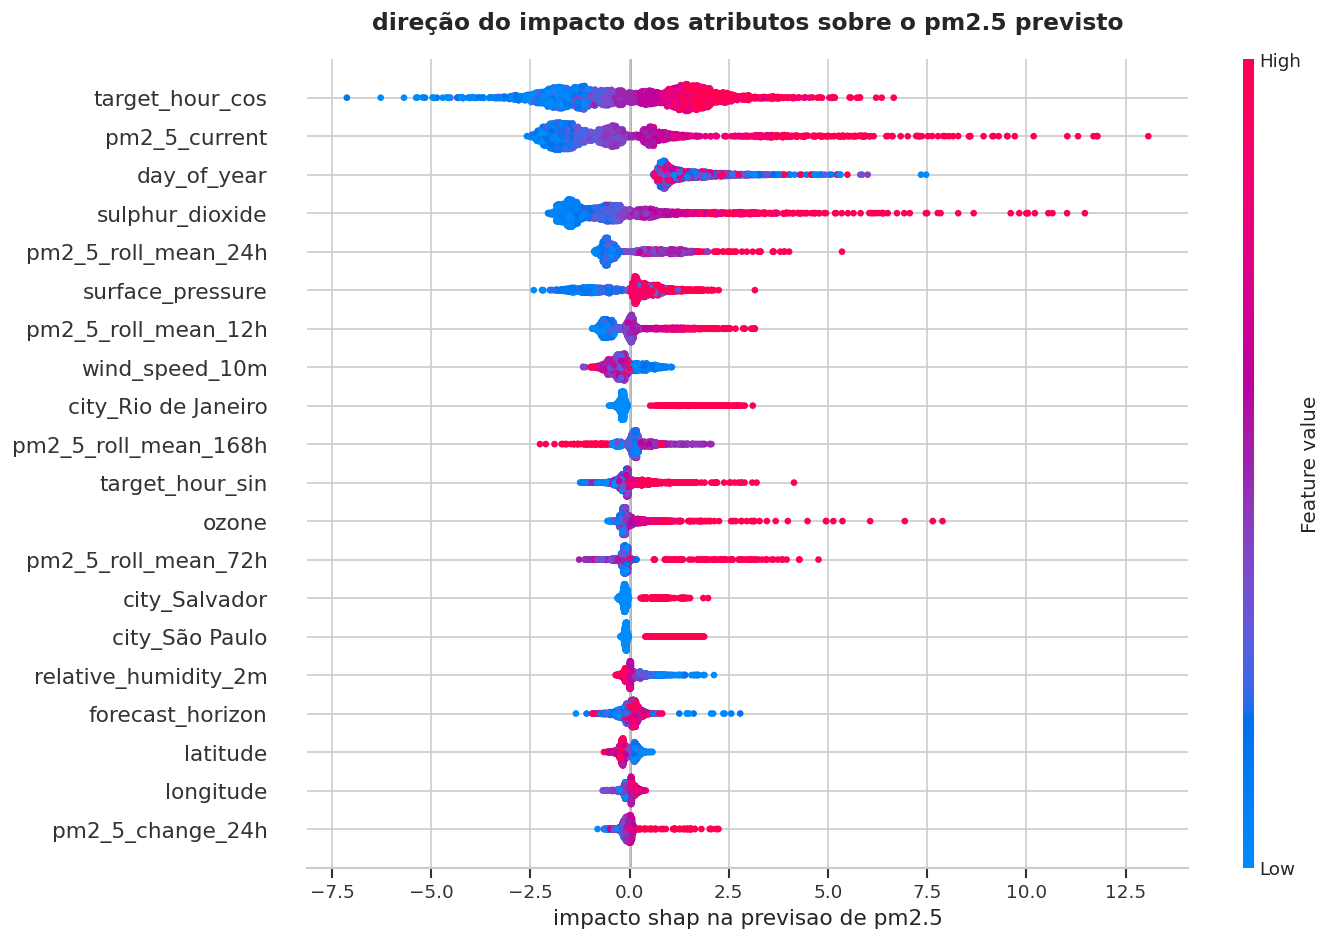

ALERTA MAIS SEVERO PREVISTO NO TESTE
Cidade: São Paulo
Origem da previsão: 2026-07-16 01:00:00+00:00
Horizonte: 3 horas
Horário previsto: 2026-07-16 04:00:00+00:00
PM2.5 previsto: 65.76 µg/m³
PM2.5 observado: 53.00 µg/m³
Risco previsto: alto


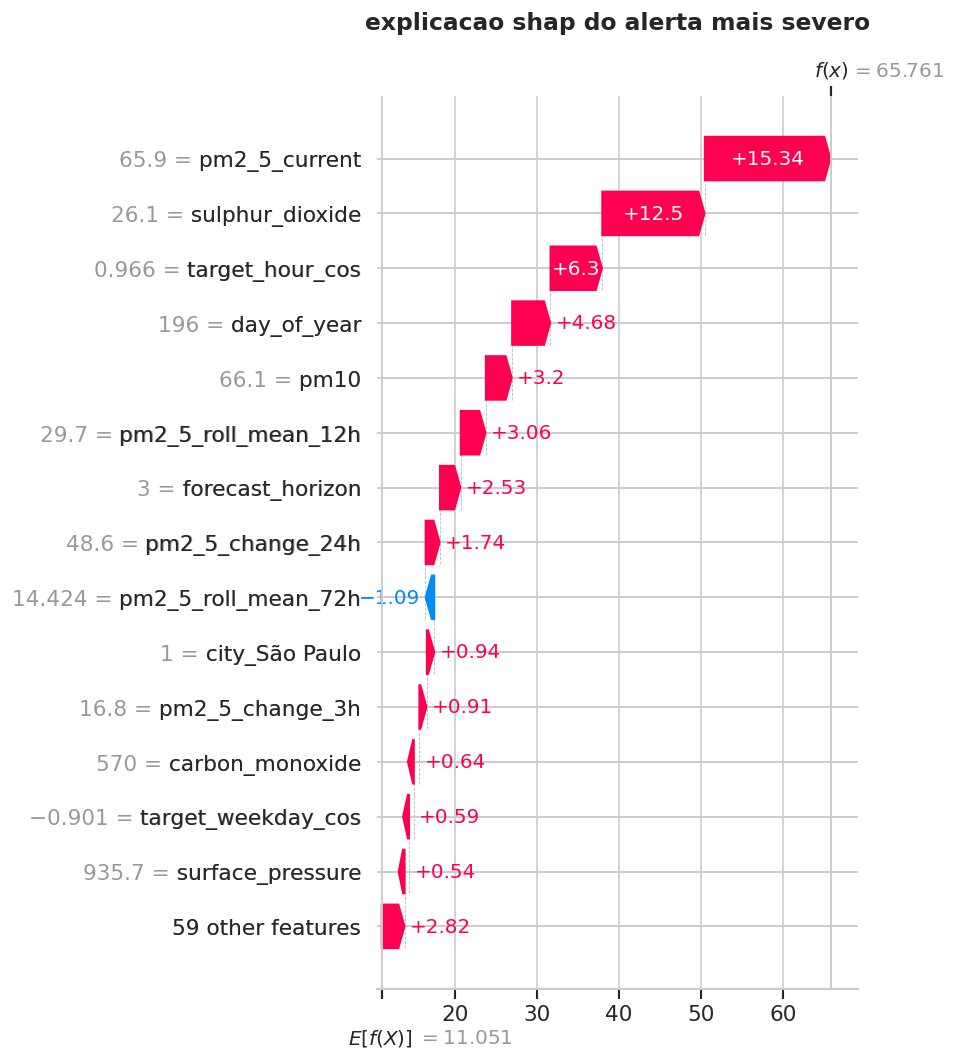

,feature,mean_absolute_shap
57,target_hour_cos,1.5194
26,pm2_5_current,1.5074
16,day_of_year,1.4137
4,sulphur_dioxide,1.2045
40,pm2_5_roll_mean_24h,0.6774
8,surface_pressure,0.6712
38,pm2_5_roll_mean_12h,0.4882
10,wind_speed_10m,0.3234
70,city_Rio de Janeiro,0.3130
44,pm2_5_roll_mean_168h,0.2861


In [ ]:
SHAP_SAMPLE_SIZE= 2_500

transformed_feature_names= (
    final_preprocessor
    .get_feature_names_out()
    .tolist()
)
rng= np.random.default_rng(SEED)
shap_sample_positions= rng.choice(
    len(X_test_transformed),
    size=min(SHAP_SAMPLE_SIZE, len(X_test_transformed)),
    replace=False,
)
X_shap_sample= X_test_transformed[shap_sample_positions]

shap_explainer= shap.TreeExplainer(xgb_model)
shap_values= shap_explainer.shap_values(X_shap_sample)


if isinstance(shap_values, list):

  shap_values_for_importance = np.mean(np.abs(np.stack(shap_values, axis=-1)), axis=-1)
else:
  shap_values_for_importance = shap_values

global_shap_importance= (
    pd.DataFrame({
        'feature': transformed_feature_names,
        'mean_absolute_shap': np.abs(shap_values_for_importance).mean(axis=0),
    })
    .sort_values(
        'mean_absolute_shap', ascending=False
    )
)
top_shap_features= (
    global_shap_importance
    .head(20)
    .sort_values('mean_absolute_shap')
)
global_shap_fig= px.bar(
  top_shap_features,
  x='mean_absolute_shap',
  y='feature',
  orientation='h',
  title='impacto global dos atributos nas previsoes de pm2.5',
  labels={
      'mean_absolute_shap': 'media de |shap|',
      'feature': 'atributo',
  },
  color='mean_absolute_shap',
  color_continuous_scale='tealgrn',
)
global_shap_fig.update_layout(
    template='plotly_white',
    height=650,
    coloraxis_showscale=False,
)
global_shap_fig.show()

plt.figure(figsize=(12,8))

shap.summary_plot(
    shap_values_for_importance,
    X_shap_sample,
    feature_names=transformed_feature_names,
    max_display=20,
    show=False,
    plot_size=None,
)

plt.title(
    'direção do impacto dos atributos sobre o pm2.5 previsto',
    fontsize=14,
    fontweight='bold',
    pad=18,
)
plt.xlabel('impacto shap na previsao de pm2.5')
plt.tight_layout()
plt.show()

critical_position= int(np.argmax(xgb_predictions))
critical_features= X_test_transformed[
    critical_position:critical_position+1
]
critical_shap_values= shap_explainer.shap_values(
    critical_features
)

if isinstance(critical_shap_values, list):
  if len(critical_shap_values) == 1:
    critical_shap_values = critical_shap_values[0]
  else:

    pass

critical_shap_values= np.asarray(critical_shap_values)[0]

expected_value= float(
  np.asarray(shap_explainer.expected_value).reshape(-1)[0]
)

critical_event= test_df.iloc[critical_position]

print("ALERTA MAIS SEVERO PREVISTO NO TESTE")
print(f"Cidade: {critical_event['city']}")
print(f"Origem da previsão: {critical_event['timestamp_utc']}")
print(f"Horizonte: {critical_event['forecast_horizon']} horas")
print(f"Horário previsto: {critical_event['target_timestamp_utc']}")
print(f"PM2.5 previsto: {xgb_predictions[critical_position]:.2f} µg/m³")
print(f"PM2.5 observado: {critical_event['target_pm2_5']:.2f} µg/m³")
print(
    "Risco previsto: "
    f"{pm25_to_risk([xgb_predictions[critical_position]])[0]}"
)


critical_explanation = shap.Explanation(
    values=critical_shap_values,
    base_values=expected_value,
    data=critical_features[0],
    feature_names=transformed_feature_names
)

shap.plots.waterfall(
    critical_explanation,
    max_display=15,
    show=False,
)
plt.title(
  'explicacao shap do alerta mais severo',
  fontsize=14,
  fontweight='bold',
  pad=18,
)
plt.tight_layout()
plt.show()
display(
    global_shap_importance.head(20).style
    .format({'mean_absolute_shap': '{:.4f}'})
    .background_gradient(
        subset=['mean_absolute_shap'],
        cmap='Greens',
    )
)

In [ ]:
error_analysis_df= xgb_evaluation_df.copy()

error_analysis_df['squared_error']= (
    error_analysis_df['residual'] ** 2
)
error_analysis_df['underprediction']= (
    error_analysis_df['residual'] > 0
).astype('int8')

error_by_risk= (
    error_analysis_df
    .groupby('target_risk', observed=True)
    .agg(
        observations=('target_pm2_5', 'size'),
        MAE=('absolute_error', 'mean'),
        RMSE=(
            'squared_error',
            lambda values: np.sqrt(values.mean()),
        ),
        bias= ('residual', 'mean'),
        underprediction_rate=(
            'underprediction',
            lambda values: values.mean() * 100,
        ),
    )
    .reindex(RISK_LABELS)
    .reset_index()
)
error_by_city= (
    error_analysis_df
    .groupby('city', observed=True)
    .agg(
        observations=('target_pm2_5', 'size'),
        MAE=('absolute_error', 'mean'),
        RMSE=(
            'squared_error',
            lambda values: np.sqrt(values.mean()),
        ),
        bias= ('residual', 'mean'),
        underprediction_rate=(
          'underprediction',
          lambda values: values.mean() * 100,
        ),
    )
    .sort_values('MAE', ascending=False)
    .reset_index()
)
print('ERRO POR NIVEL REAL DE RISCO')
print('bias positivo indica tendencia de subestimação')
display(
    error_by_risk.style
    .format({
        "MAE": "{:.3f}",
        "RMSE": "{:.3f}",
        "bias": "{:+,.3f}",
        "underprediction_rate": "{:.1f}%",
    })
    .background_gradient(
        subset=["MAE", "RMSE"],
        cmap="RdYlGn_r",
    )
)

print("ERRO POR CIDADE")
display(
    error_by_city.style
    .format({
        "MAE": "{:.3f}",
        "RMSE": "{:.3f}",
        "bias": "{:+,.3f}",
        "underprediction_rate": "{:.1f}%",
    })
    .background_gradient(
        subset=["MAE", "RMSE"],
        cmap="RdYlGn_r",
    )
)

# Mapa de erro por cidade e horizonte
city_horizon_mae = (
    error_analysis_df
    .groupby(
        ["city", "forecast_horizon"],
        observed=True,
    )["absolute_error"]
    .mean()
    .unstack()
    .reindex(error_by_city["city"])
)

error_heatmap = go.Figure(
    data=go.Heatmap(
        z=city_horizon_mae.values,
        x=city_horizon_mae.columns,
        y=city_horizon_mae.index,
        colorscale="YlOrRd",
        colorbar={"title": "MAE<br>µg/m³"},
        hovertemplate=(
            "Cidade: %{y}<br>"
            "Horizonte: %{x}h<br>"
            "MAE: %{z:.2f} µg/m³"
            "<extra></extra>"
        ),
    )
)

error_heatmap.update_layout(
    title="MAE por cidade e horizonte de previsão",
    template="plotly_white",
    height=530,
    xaxis_title="Horizonte (horas)",
    yaxis_title="Cidade",
    xaxis={"dtick": 1},
)
error_heatmap.show()

# Resíduos em função da concentração real
residual_sample = error_analysis_df.sample(
    n=min(15_000, len(error_analysis_df)),
    random_state=SEED,
)

residual_fig = px.scatter(
    residual_sample,
    x="target_pm2_5",
    y="residual",
    color="target_risk",
    opacity=0.35,
    title="Comportamento dos erros conforme a concentração real",
    labels={
        "target_pm2_5": "PM2.5 observado (µg/m³)",
        "residual": "Resíduo: observado - previsto (µg/m³)",
        "target_risk": "Risco real",
    },
    category_orders={"target_risk": RISK_LABELS},
    color_discrete_map={
        "baixo": "#16A34A",
        "medio": "#F59E0B",
        "alto": "#DC2626",
    },
)

residual_fig.add_hline(
    y=0,
    line_dash="dash",
    line_color="#111827",
)

residual_fig.update_layout(
    template="plotly_white",
    height=540,
)
residual_fig.show()

# Casos com maiores erros absolutos
worst_errors = (
    error_analysis_df
    .nlargest(15, "absolute_error")
    [
        [
            "city",
            "target_timestamp_utc",
            "forecast_horizon",
            "target_pm2_5",
            "prediction_pm2_5",
            "residual",
            "absolute_error",
            "target_risk",
            "prediction_risk",
        ]
    ]
)

print("15 MAIORES ERROS DO HOLDOUT")
display(
    worst_errors.style.format({
        "target_pm2_5": "{:.2f}",
        "prediction_pm2_5": "{:.2f}",
        "residual": "{:+,.2f}",
        "absolute_error": "{:.2f}",
    })
)

high_risk_events = error_analysis_df[
    error_analysis_df["target_risk"].astype("string") == "alto"
]

if not high_risk_events.empty:
    high_risk_recall = (
        high_risk_events["prediction_risk"].eq("alto").mean()
    )

    print(
        "\nSensibilidade aos episódios de risco alto "
        f"pela regressão: {high_risk_recall:.2%}"
    )
else:
    print(
        "\nO holdout não contém episódios de risco alto; "
        "essa sensibilidade não pôde ser estimada."
    )

ERRO POR NIVEL REAL DE RISCO
bias positivo indica tendencia de subestimação


,target_risk,observations,MAE,RMSE,bias,underprediction_rate
0,baixo,68201,3.831,5.543,-2.825,26.4%
1,medio,8293,6.124,8.221,+0.753,58.6%
2,alto,1386,20.187,23.058,+18.745,91.6%


ERRO POR CIDADE


,city,observations,MAE,RMSE,bias,underprediction_rate
0,São Paulo,7788,10.468,13.645,-5.986,18.0%
1,Rio de Janeiro,7788,7.770,9.672,-5.336,16.0%
2,Porto Alegre,7788,4.259,5.347,-3.195,19.4%
3,Curitiba,7788,3.794,4.760,-1.949,27.0%
4,Salvador,7788,3.699,5.203,-1.532,26.1%
5,Belo Horizonte,7788,3.666,5.772,-1.261,22.4%
6,Brasília,7788,3.113,4.225,-0.546,37.3%
7,Manaus,7788,2.563,3.214,-0.522,42.3%
8,Fortaleza,7788,2.333,2.974,-0.484,44.1%
9,Recife,7788,2.001,2.693,+0.205,57.0%


15 MAIORES ERROS DO HOLDOUT


,city,target_timestamp_utc,forecast_horizon,target_pm2_5,prediction_pm2_5,residual,absolute_error,target_risk,prediction_risk
1908,São Paulo,2026-07-11 08:00:00+00:00,13,80.80,21.96,+58.84,58.84,alto,medio
1907,São Paulo,2026-07-11 07:00:00+00:00,12,82.70,24.55,+58.15,58.15,alto,medio
1909,São Paulo,2026-07-11 09:00:00+00:00,14,78.00,21.25,+56.75,56.75,alto,medio
2149,São Paulo,2026-07-11 10:00:00+00:00,14,76.80,23.31,+53.49,53.49,alto,medio
1910,São Paulo,2026-07-11 10:00:00+00:00,15,76.80,23.53,+53.27,53.27,alto,medio
1906,São Paulo,2026-07-11 06:00:00+00:00,11,83.80,30.97,+52.83,52.83,alto,medio
2147,São Paulo,2026-07-11 08:00:00+00:00,12,80.80,28.31,+52.49,52.49,alto,medio
2385,São Paulo,2026-07-11 07:00:00+00:00,10,82.70,30.31,+52.39,52.39,alto,medio
2386,São Paulo,2026-07-11 08:00:00+00:00,11,80.80,29.16,+51.64,51.64,alto,medio
2146,São Paulo,2026-07-11 07:00:00+00:00,11,82.70,31.20,+51.50,51.50,alto,medio



Sensibilidade aos episódios de risco alto pela regressão: 32.18%


In [ ]:
latest_origins= (
    historical_df.loc[
        historical_df['pm2_5_lag_12h'].notna()
    ]
    .sort_values(['city', 'timestamp_utc'])
    .groupby('city', observed=True)
    .tail(1)
    .copy()
)
if latest_origins['city'].nunique() != clean_df['city'].nunique():
  missing_cities= (
      set(clean_df['city'].unique())
      -set(latest_origins['city'].unique())
  )
  print(f'cidades sem historico suficiente: {sorted(missing_cities)}')
forecast_frames= []

for horizon in range(1, FORECAST_HORIZON + 1):
  horizon_input= latest_origins.copy()
  horizon_input['forecast_horizon']= horizon
  horizon_input['target_timestamp_utc'] =(
      horizon_input['timestamp_utc']
      + pd.to_timedelta(horizon, unit='h')
  )

  target_local_datetime = (
      horizon_input['local_datetime']
      + pd.to_timedelta(horizon, unit='h')
  )
  target_hour= target_local_datetime.dt.hour
  target_weekday= target_local_datetime.dt.dayofweek

  horizon_input['target_local_datetime']= target_local_datetime
  horizon_input['target_hour_sin']= np.sin(
    2 * np.pi * target_hour / 24
  )
  horizon_input['target_hour_cos']= np.cos(
    2 * np.pi * target_hour / 24
  )
  horizon_input['target_weekday_sin']= np.sin(
    2 * np.pi * target_weekday / 7
  )
  horizon_input['target_weekday_cos']= np.cos(
    2 * np.pi * target_weekday / 7
  )

  forecast_frames.append(horizon_input)
forecast_input_df= (
    pd.concat(forecast_frames, ignore_index=True)
    .sort_values(['city', 'forecast_horizon'])
    .reset_index(drop=True)
)

missing_model_features= (
    set(model_features) - set(forecast_input_df.columns)
)

if missing_model_features:
  raise ValueError(
      f'atributos ausentes para inferencia: {sorted(missing_model_features)}'
  )
X_forecast= final_preprocessor.transform(
    forecast_input_df[model_features]
).astype(np.float32)

forecast_pm25= np.clip(
    xgb_model.predict(X_forecast),
    a_min=0,
    a_max=None,
)
forecast_risk_probabilities= risk_classifier.predict_proba(
    X_forecast
)
classifier_risk_codes= np.argmax(
    forecast_risk_probabilities,
    axis=1,
)
concentration_risk= pm25_to_risk(forecast_pm25)
concentration_risk_codes= np.array([
    risk_to_code[risk]
    for risk in concentration_risk
])
operational_risk_codes= np.maximum(concentration_risk_codes, classifier_risk_codes)
operational_risk = np.array([
    code_to_risk[code]
    for code in operational_risk_codes
])
forecast_df= forecast_input_df[
   [
       'city',
       'timezone',
       'timestamp_utc',
       'target_timestamp_utc',
       'target_local_datetime',
       'forecast_horizon', # Fixed unterminated string literal
   ]
].copy()

forecast_df['predicted_pm2_5']= forecast_pm25
forecast_df['risk_by_concentration']= concentration_risk
forecast_df['classifier_risk']= [
    code_to_risk[code]
    for code in classifier_risk_codes
]
forecast_df['operational_risk']= operational_risk
forecast_df['probability_low']= forecast_risk_probabilities[:, 0]
forecast_df['probability_medium']= forecast_risk_probabilities[:,1]
forecast_df['probability_high']= forecast_risk_probabilities[:,2]
forecast_df['classifier_confidence']= (
    forecast_risk_probabilities.max(axis=1)
)
health_recommendations= {
    'baixo': (
        'condições favoraveis; manter monitoramento de rotina'
    ),
    'medio':(
        'grupos sensiveis devem reduzir esforço intenso e prolongado ao ar livre'
    ),
    'alto':(
        'emitir alerta; reduzir atividades externos e proteger gropos vulneraveis'
    ),
}
forecast_df['health_recommendation']= (
    forecast_df['operational_risk']
    .map(health_recommendations)
)

severity_order= {
    'baixo': 0,
    'medio': 1,
    'alto': 2 ,
}
forecast_df['severity_code']= (
    forecast_df['operational_risk']
    .map(severity_order)
)
city_alert_records=[]

for city, group in forecast_df.groupby('city', observed=True):
  peak_row= group.loc[group['predicted_pm2_5'].idxmax()]
  maximum_severity= int(group['severity_code'].max())
  city_risk= code_to_risk[maximum_severity]

  city_alert_records.append({
      'city': city,
      'maximum_risk': city_risk,
      'peak_pm2_5': peak_row['predicted_pm2_5'],
      'peak_local_time': peak_row['target_local_datetime'],
      'peak_horizon': peak_row['forecast_horizon'],
      'maximum_high_probability': group['probability_high'].max(),
      'recommendation': health_recommendations[city_risk],
  })
city_alert_summary= (
    pd.DataFrame(city_alert_records)
    .assign(
        severity=lambda frame: frame['maximum_risk'].map(
            severity_order
        )
    )
    .sort_values(
        ['severity', 'peak_pm2_5'],
        ascending=[False, False],
    )
    .drop(columns='severity')
    .reset_index(drop=True)
)
print(
    'previsões geradas a partir de: '
    f"{forecast_input_df['timestamp_utc'].max()}"
)
print(f'previsões produzidas: {len(forecast_df):,}')
print(f'cidades monitoradas: {forecast_df['city'].nunique()}')

display(
    city_alert_summary.style
    .format({
        "peak_pm2_5": "{:.2f} µg/m³",
        "maximum_high_probability": "{:.1%}",
    })
    .applymap(
        lambda value: (
            "background-color: #FEE2E2; color: #991B1B"
            if value == "alto"
            else (
                "background-color: #FEF3C7; color: #92400E"
                if value == "medio"
                else "background-color: #DCFCE7; color: #166534"
            )
        ),
        subset=["maximum_risk"],
    )
)

forecast_matrix= (
    forecast_df
    .pivot(
        index='city',
        columns='forecast_horizon',
        values='predicted_pm2_5',
    )
    .reindex(city_alert_summary['city'])
)

forecast_heatmap= go.Figure(
  data=go.Heatmap(
      z=forecast_matrix.values,
      x=forecast_matrix.columns,
      y=forecast_matrix.index,
      colorscale= [
          [0.00, "#16A34A"],
          [0.35, "#FACC15"],
          [0.65, "#F97316"],
          [1.00, "#DC2626"],
      ],
      colorbar={'title': 'pm2.5'},
      hovertemplate=(
          "Cidade: %{y}<br>"
          "Horizonte: %{x}h<br>"
          "PM2.5 previsto: %{z:.2f} µg/m³"
          "<extra></extra>"
      ),
  )
)
forecast_heatmap.update_layout(
    title='previsao de pm2.5 para as proximas 24 horas',
    template='plotly_white',
    height=540,
    xaxis_title='horizonte de previsao',
    yaxis_title= 'cidade',
    xaxis={'dtick': 1},
)
forecast_heatmap.show()

previsões geradas a partir de: 2026-07-24 12:00:00+00:00
previsões produzidas: 240
cidades monitoradas: 10


,city,maximum_risk,peak_pm2_5,peak_local_time,peak_horizon,maximum_high_probability,recommendation
0,São Paulo,alto,20.38 µg/m³,2026-07-25 04:00:00,19,47.3%,emitir alerta; reduzir atividades externos e proteger gropos vulneraveis
1,Rio de Janeiro,medio,24.28 µg/m³,2026-07-24 23:00:00,14,45.5%,grupos sensiveis devem reduzir esforço intenso e prolongado ao ar livre
2,Belo Horizonte,medio,22.37 µg/m³,2026-07-25 00:00:00,15,15.8%,grupos sensiveis devem reduzir esforço intenso e prolongado ao ar livre
3,Salvador,medio,20.85 µg/m³,2026-07-25 02:00:00,17,31.6%,grupos sensiveis devem reduzir esforço intenso e prolongado ao ar livre
4,Porto Alegre,baixo,11.06 µg/m³,2026-07-25 00:00:00,15,1.7%,condições favoraveis; manter monitoramento de rotina
5,Brasília,baixo,10.67 µg/m³,2026-07-25 00:00:00,15,3.0%,condições favoraveis; manter monitoramento de rotina
6,Curitiba,baixo,9.33 µg/m³,2026-07-25 00:00:00,15,0.5%,condições favoraveis; manter monitoramento de rotina
7,Manaus,baixo,9.25 µg/m³,2026-07-25 00:00:00,16,0.2%,condições favoraveis; manter monitoramento de rotina
8,Recife,baixo,8.67 µg/m³,2026-07-24 20:00:00,11,0.2%,condições favoraveis; manter monitoramento de rotina
9,Fortaleza,baixo,6.90 µg/m³,2026-07-25 00:00:00,15,0.1%,condições favoraveis; manter monitoramento de rotina


In [ ]:
from IPython.display import Markdown

require_objects= [
    'raw_df',
    'clean_df',
    'development_df',
    'test_df',
    'xgb_model',
    'risk_classifier',
    'xgb_predictions',
    'forecast_df',
    'city_alert_summary',
]
missing_objects= [
    object_name
    for object_name in require_objects # Corrected typo from 'required_objecs' to 'require_objects'
    if object_name not in globals()
]
if missing_objects:
  raise RuntimeError(
      'execute as celulas anteriores, objetos ausentes: '
      f'{missing_objects}'
  )
validation_checks= {
    'dados coletados': not raw_df.empty,
    'sem duplicidades cidade-horario': not clean_df.duplicated(
        ['city', 'timestamp_utc']
    ).any(),
    'isolamento temporal do holdout': (
        development_df['target_timestamp_utc'].max()
        < test_df['timestamp_utc'].min()
    ),
    'previsoes alinhadas ao teste': (
        len(xgb_predictions) == len(test_df)
    ),
    'previsoes nao negativas': (
        np.asarray(xgb_predictions) >= 0
    ).all(),
    'probabilidades normalizadas': np.allclose(
        risk_probabilities.sum(axis=1),
        1.0,
        atol=1e-5,
    ),
    'todos os horizontes disponiveis':(
        forecast_df
        .groupby('city', observed=True)['forecast_horizon']
        .nunique()
        .eq(FORECAST_HORIZON)
        .all()
    ),
    'classes operacionais validas':(
        forecast_df['operational_risk']
        .isin(RISK_LABELS) # Changed .asin to .isin
        .all()
    ),
}
validation_df= pd.DataFrame({
    'verificacao': list(validation_checks.keys()), # Corrected to use .keys() for 'verificacao'
    'resultado': [
        'APROVADO' if result else 'FALHOU' # Corrected syntax error
        for result in validation_checks.values()
    ],
})

failed_checks= [
    check
    for check, result in validation_checks.items()
    if not result
]

display(
    validation_df.style.applymap(
        lambda value: (
            "background-color: #DCFCE7; color: #166534"
            if value == "APROVADO"
            else (
                "background-color: #FEE2E2; color: #991B1B"
                if value == "FALHOU"
                else ""
            )
        ),
        subset=["resultado"],
    )
)
if failed_checks:
  raise AssertionError(
  f'validações nao aprovadas: {failed_checks}'
  )
baseline_mae= float(baseline_metrics['MAE']) # Corrected 'mae' to 'MAE'
xgb_mae= float(xgb_metrics['MAE']) # Corrected 'mae' to 'MAE'
mae_change_percent= (
    (baseline_mae - xgb_mae) / baseline_mae * 100
)

if mae_change_percent >= 0:
  performance_statement= (
      f'o xgboost reduziu o mae em ** {mae_change_percent:.1f}%** '
      'em relacao a persistencia'
  )
else:
    performance_statement = (
        f"O XGBoost apresentou MAE **{abs(mae_change_percent):.1f}% maior** "
        "que a persistência, indicando necessidade de revisão."
    )
high_alert_cities= city_alert_summary.loc[
    city_alert_summary['maximum_risk'] == 'alto',
    'city',
].tolist()

# Define medium_alert_cities for the report
medium_alert_cities= city_alert_summary.loc[
    city_alert_summary['maximum_risk'] == 'medio',
    'city',
].tolist()

def format_city_list(cities):
  return ', '.join(cities) if cities else 'nenhuma'

worst_city= error_by_city.iloc[0]
best_city= error_by_city.iloc[-1]

executive_report = f"""
# Relatório executivo: PM2.5 e risco à saúde

## Resultado do modelo

- **MAE do XGBoost:** {xgb_metrics['MAE']:.2f} µg/m³
- **RMSE do XGBoost:** {xgb_metrics['RMSE']:.2f} µg/m³
- **R² do XGBoost:** {xgb_metrics['R2']:.3f}
- **F1 macro do classificador:** {classification_results['f1_macro']:.3f}
- **F1 ponderado:** {classification_results['f1_weighted']:.3f}
- **ROC-AUC multiclasse:** {classification_results['roc_auc_ovr']:.3f}

{performance_statement}

O maior MAE ocorreu em **{worst_city['city']}**
({worst_city['MAE']:.2f} µg/m³), enquanto o menor ocorreu em
**{best_city['city']}** ({best_city['MAE']:.2f} µg/m³).

## Alertas para as próximas 24 horas

- **Risco alto:** {format_city_list(high_alert_cities)}
- **Risco médio:** {format_city_list(medium_alert_cities)}
- **Origem mais recente:** {forecast_df['timestamp_utc'].max()}
- **Horizonte monitorado:** 1 a {FORECAST_HORIZON} horas

## Recomendações para políticas públicas

1. Integrar as previsões a painéis municipais e atualizar os alertas a cada hora.
2. Acionar comunicação preventiva quando a probabilidade de risco alto aumentar, mesmo antes de ultrapassar 35 µg/m³.
3. Priorizar crianças, idosos, gestantes e pessoas com doenças respiratórias ou cardiovasculares.
4. Em risco médio, recomendar redução de exercícios intensos e prolongados ao ar livre para grupos sensíveis.
5. Em risco alto, avaliar restrições temporárias a queimadas, obras com poeira e tráfego de veículos pesados.
6. Combinar o sistema com estações regulatórias locais antes de emitir alertas oficiais.
7. Monitorar MAE, recall de risco alto e drift dos atributos após cada atualização.

## Limitações

1. O Open-Meteo utiliza estimativas atmosféricas em grade, que não substituem medições de estações regulatórias.
2. A janela de {HISTORICAL_DAYS} dias é adequada para padrões recentes, mas não representa toda a sazonalidade anual.
3. Os limites de 15 e 35 µg/m³ são faixas operacionais deste projeto e não constituem diagnóstico médico.
4. O modelo usa clima atual, tendências e histórico; não possui arquivos históricos de previsões meteorológicas emitidas em cada instante.
5. Incêndios, queimadas, tráfego, obras e mudanças regulatórias não foram incluídos como fontes externas específicas.
6. Probabilidades do classificador não garantem certeza clínica e devem ser recalibradas periodicamente.
7. O desempenho futuro pode se degradar por mudanças climáticas, urbanas ou na fonte dos dados.
"""

display(Markdown(executive_report))
print(
  f'validacao interna concluida: '
  f'{sum(validation_checks.values())}/{len(validation_checks)} verificações aprovadas'
)

,verificacao,resultado
0,dados coletados,APROVADO
1,sem duplicidades cidade-horario,APROVADO
2,isolamento temporal do holdout,APROVADO
3,previsoes alinhadas ao teste,APROVADO
4,previsoes nao negativas,APROVADO
5,probabilidades normalizadas,APROVADO
6,todos os horizontes disponiveis,APROVADO
7,classes operacionais validas,APROVADO



# Relatório executivo: PM2.5 e risco à saúde

## Resultado do modelo

- **MAE do XGBoost:** 4.37 µg/m³
- **RMSE do XGBoost:** 6.60 µg/m³
- **R² do XGBoost:** 0.263
- **F1 macro do classificador:** 0.513
- **F1 ponderado:** 0.815
- **ROC-AUC multiclasse:** 0.867

o xgboost reduziu o mae em ** 3.0%** em relacao a persistencia

O maior MAE ocorreu em **São Paulo**
(10.47 µg/m³), enquanto o menor ocorreu em
**Recife** (2.00 µg/m³).

## Alertas para as próximas 24 horas

- **Risco alto:** São Paulo
- **Risco médio:** Rio de Janeiro, Belo Horizonte, Salvador
- **Origem mais recente:** 2026-07-24 12:00:00+00:00
- **Horizonte monitorado:** 1 a 24 horas

## Recomendações para políticas públicas

1. Integrar as previsões a painéis municipais e atualizar os alertas a cada hora.
2. Acionar comunicação preventiva quando a probabilidade de risco alto aumentar, mesmo antes de ultrapassar 35 µg/m³.
3. Priorizar crianças, idosos, gestantes e pessoas com doenças respiratórias ou cardiovasculares.
4. Em risco médio, recomendar redução de exercícios intensos e prolongados ao ar livre para grupos sensíveis.
5. Em risco alto, avaliar restrições temporárias a queimadas, obras com poeira e tráfego de veículos pesados.
6. Combinar o sistema com estações regulatórias locais antes de emitir alertas oficiais.
7. Monitorar MAE, recall de risco alto e drift dos atributos após cada atualização.

## Limitações

1. O Open-Meteo utiliza estimativas atmosféricas em grade, que não substituem medições de estações regulatórias.
2. A janela de 90 dias é adequada para padrões recentes, mas não representa toda a sazonalidade anual.
3. Os limites de 15 e 35 µg/m³ são faixas operacionais deste projeto e não constituem diagnóstico médico.
4. O modelo usa clima atual, tendências e histórico; não possui arquivos históricos de previsões meteorológicas emitidas em cada instante.
5. Incêndios, queimadas, tráfego, obras e mudanças regulatórias não foram incluídos como fontes externas específicas.
6. Probabilidades do classificador não garantem certeza clínica e devem ser recalibradas periodicamente.
7. O desempenho futuro pode se degradar por mudanças climáticas, urbanas ou na fonte dos dados.


validacao interna concluida: 8/8 verificações aprovadas


In [ ]:
from plotly.subplots import make_subplots

if 'forecast_df' not in globals() or forecast_df.empty:
  raise RuntimeError('execute primeiro a celula de previsao operacional')
dashboard_cities= city_alert_summary['city'].tolist()
initial_city= dashboard_cities[0]
traces_per_day= 4

dashboard= make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.12,
    row_heights=[0.58, 0.42],
    subplot_titles=[
        'concentração prevista de pm2.5',
        'probabilidades por nivel de risco',
    ],
)
risk_colors = {
  "baixo": "#16A34A",
  "medio": "#F59E0B",
  "alto": "#DC2626",
}

for city_index, city in enumerate(dashboard_cities):
  city_forecast= (
      forecast_df.loc[forecast_df['city'] == city]
      .sort_values('forecast_horizon')
  )
  is_initial_city= city == initial_city

  dashboard.add_trace(
      go.Scatter(
          x=city_forecast['target_local_datetime'],
          y=city_forecast['predicted_pm2_5'],
          mode='lines+markers',
          name='pm2.5 previsto',
          visible= is_initial_city,
          line={
              'color': '#2563EB',
              'width': 3,
          },
          marker={
              'size': 7,
              'color': city_forecast['severity_code'],
              'colorscale': [
                  [0.0, "#16A34A"],
                  [0.5, "#F59E0B"],
                  [1.0, "#DC2626"],
              ],
              'cmin': 0,
              'cmax': 2,
          },
          customdata=np.column_stack([
              city_forecast['forecast_horizon'],
              city_forecast['operational_risk'],
          ]),
          hovertemplate= (
              "<b>%{x|%d/%m %H:%M}</b><br>"
              "Horizonte: %{customdata[0]}h<br>"
              "PM2.5: %{y:.2f} µg/m³<br>"
              "Risco: %{customdata[1]}"
              "<extra></extra>"
      ),
      ), # Corrected: moved row and col out of go.Scatter
      row=1,
      col=1,
  )
  for risk_name, probability_column in [
        ("baixo", "probability_low"),
        ("medio", "probability_medium"),
        ("alto", "probability_high"),
    ]:
        dashboard.add_trace(
            go.Scatter(
                x=city_forecast["target_local_datetime"],
                y=city_forecast[probability_column],
                mode="lines",
                name=f"Risco {risk_name}",
                visible=is_initial_city,
                line={
                    "color": risk_colors[risk_name],
                    "width": 2.5,
                },
                fill="tozeroy" if risk_name == "alto" else None,
                fillcolor=(
                    "rgba(220, 38, 38, 0.08)"
                    if risk_name == "alto"
                    else None
                ),
                hovertemplate=(
                    "<b>%{x|%d/%m %H:%M}</b><br>"
                    f"Probabilidade de risco {risk_name}: "
                    "%{y:.1%}<extra></extra>"
                ),
            ),
            row=2,
            col=1,
        )

# Faixas operacionais de concentração
dashboard.add_hrect(
    y0=0,
    y1=15,
    fillcolor="#DCFCE7",
    opacity=0.25,
    line_width=0,
    row=1,
    col=1,
)

dashboard.add_hrect(
    y0=15,
    y1=35,
    fillcolor="#FEF3C7",
    opacity=0.25,
    line_width=0,
    row=1,
    col=1,
)

upper_limit = max(
    50,
    float(forecast_df["predicted_pm2_5"].max()) * 1.15,
)

dashboard.add_hrect(
    y0=35,
    y1=upper_limit,
    fillcolor="#FEE2E2",
    opacity=0.25,
    line_width=0,
    row=1,
    col=1,
)

dashboard.add_hline(
    y=15,
    line_dash="dash",
    line_color="#F59E0B",
    row=1,
    col=1,
)

dashboard.add_hline(
    y=35,
    line_dash="dash",
    line_color="#DC2626",
    row=1,
    col=1,
)

# Botões para alternar entre cidades
city_buttons = []

for city_index, city in enumerate(dashboard_cities):
    trace_visibility = [False] * (
        len(dashboard_cities) * traces_per_day
    )

    first_trace = city_index * traces_per_day

    for trace_offset in range(traces_per_day):
        trace_visibility[first_trace + trace_offset] = True

    city_buttons.append({
        "label": city,
        "method": "update",
        "args": [
            {"visible": trace_visibility},
            {
                "title": (
                    "Previsão de PM2.5 e risco à saúde "
                    f"nas próximas 24 horas: {city}"
                )
            },
        ],
    })

dashboard.update_layout(
    title=((
        "Previsão de PM2.5 e risco à saúde "
        f"nas próximas 24 horas: {initial_city}"
    )),
    template="plotly_white",
    height=800,
    hovermode="x unified",
    updatemenus=[{
        "buttons": city_buttons,
        "direction": "down",
        "showactive": True,
        "active": 0,
        "x": 1,
        "xanchor": "right",
        "y": 1.16,
        "yanchor": "top",
    }],
    legend={
        "orientation": "h",
        "yanchor": "bottom",
        "y": 1.02,
        "xanchor": "left",
        "x": 0,
    },
    margin={"t": 130},
)

dashboard.update_yaxes(
    title_text="PM2.5 (µg/m³)",
    range=[0, upper_limit],
    row=1,
    col=1,
)

dashboard.update_yaxes(
    title_text="Probabilidade",
    tickformat=".0%",
    range=[0, 1],
    row=2,
    col=1,
)

dashboard.update_xaxes(
    title_text="Data e hora local",
    tickformat="%d/%m<br>%H:%M",
    row=2,
    col=1,
)

dashboard.show()

In [ ]:
INTERVAL_CONFIDENCE= 0.90
lower_quantile= (1 - INTERVAL_CONFIDENCE) / 2
upper_quantile= 1 - lower_quantile

residual_quantiles= (
    xgb_evaluation_df
    .groupby('forecast_horizon', observed=True)['residual']
    .quantile([lower_quantile, upper_quantile])
    .unstack()
    .rename(columns={
        lower_quantile: 'residual_lower',
        upper_quantile: 'residual_upper',
    })
    .reset_index()
)

interval_evaluation_df= xgb_evaluation_df.merge(
    residual_quantiles,
    on='forecast_horizon',
    how='left',
    validate='many_to_one',
)

interval_evaluation_df = xgb_evaluation_df.merge(
    residual_quantiles,
    on="forecast_horizon",
    how="left",
    validate="many_to_one",
)

interval_evaluation_df["lower_bound"] = np.clip(
    interval_evaluation_df["prediction_pm2_5"]
    + interval_evaluation_df["residual_lower"],
    a_min=0,
    a_max=None,
)

interval_evaluation_df["upper_bound"] = np.clip(
    interval_evaluation_df["prediction_pm2_5"]
    + interval_evaluation_df["residual_upper"],
    a_min=0,
    a_max=None,
)

interval_evaluation_df["covered"] = (
    interval_evaluation_df["target_pm2_5"]
    .between(
        interval_evaluation_df["lower_bound"],
        interval_evaluation_df["upper_bound"],
        inclusive="both",
    )
)

interval_diagnostics = (
    interval_evaluation_df
    .groupby("forecast_horizon", observed=True)
    .agg(
        empirical_coverage=("covered", "mean"),
        mean_interval_width=(
            "upper_bound",
            lambda upper: (
                upper.to_numpy()
                - interval_evaluation_df.loc[
                    upper.index,
                    "lower_bound",
                ].to_numpy()
            ).mean(),
        ),
    )
    .reset_index()
)

overall_empirical_coverage = (
    interval_evaluation_df["covered"].mean()
)

# Aplica os quantis às previsões operacionais.
forecast_uncertainty_df = forecast_df.merge(
    residual_quantiles,
    on="forecast_horizon",
    how="left",
    validate="many_to_one",
)

forecast_uncertainty_df["lower_pm2_5"] = np.clip(
    forecast_uncertainty_df["predicted_pm2_5"]
    + forecast_uncertainty_df["residual_lower"],
    a_min=0,
    a_max=None,
)

forecast_uncertainty_df["upper_pm2_5"] = np.clip(
    forecast_uncertainty_df["predicted_pm2_5"]
    + forecast_uncertainty_df["residual_upper"],
    a_min=0,
    a_max=None,
)

forecast_uncertainty_df["interval_width"] = (
    forecast_uncertainty_df["upper_pm2_5"]
    - forecast_uncertainty_df["lower_pm2_5"]
)

assert (
    forecast_uncertainty_df["lower_pm2_5"]
    <= forecast_uncertainty_df["predicted_pm2_5"]
).all()

assert (
    forecast_uncertainty_df["predicted_pm2_5"]
    <= forecast_uncertainty_df["upper_pm2_5"]
).all()

print(f"Intervalo nominal: {INTERVAL_CONFIDENCE:.0%}")
print(
    "Cobertura no conjunto usado para calibração: "
    f"{overall_empirical_coverage:.1%}"
)
print(
    "A cobertura acima é diagnóstica e não representa "
    "uma validação futura independente."
)

display(
    interval_diagnostics.style
    .format({
        "empirical_coverage": "{:.1%}",
        "mean_interval_width": "{:.2f} µg/m³",
    })
    .background_gradient(
        subset=["mean_interval_width"],
        cmap="YlOrRd",
    )
)

# Exibe a cidade com maior pico previsto.
uncertainty_city = city_alert_summary.iloc[0]["city"]

city_uncertainty = (
    forecast_uncertainty_df.loc[
        forecast_uncertainty_df["city"] == uncertainty_city
    ]
    .sort_values("forecast_horizon")
)

uncertainty_fig = go.Figure()

uncertainty_fig.add_trace(
    go.Scatter(
        x=city_uncertainty["target_local_datetime"],
        y=city_uncertainty["upper_pm2_5"],
        mode="lines",
        line={"width": 0},
        name="Limite superior",
        hovertemplate=(
            "Limite superior: %{y:.2f} µg/m³"
            "<extra></extra>"
        ),
    )
)

uncertainty_fig.add_trace(
    go.Scatter(
        x=city_uncertainty["target_local_datetime"],
        y=city_uncertainty["lower_pm2_5"],
        mode="lines",
        line={"width": 0},
        fill="tonexty",
        fillcolor="rgba(37, 99, 235, 0.18)",
        name=f"Intervalo de {INTERVAL_CONFIDENCE:.0%}",
        hovertemplate=(
            "Limite inferior: %{y:.2f} µg/m³"
            "<extra></extra>"
        ),
    )
)

uncertainty_fig.add_trace(
    go.Scatter(
        x=city_uncertainty["target_local_datetime"],
        y=city_uncertainty["predicted_pm2_5"],
        mode="lines+markers",
        line={
            "color": "#2563EB",
            "width": 3,
        },
        marker={"size": 7},
        name="Previsão central",
        hovertemplate=(
            "%{x|%d/%m %H:%M}<br>"
            "PM2.5 previsto: %{y:.2f} µg/m³"
            "<extra></extra>"
        ),
    )
)

uncertainty_fig.add_hline(
    y=15,
    line_dash="dash",
    line_color="#F59E0B",
    annotation_text="Risco médio",
)

uncertainty_fig.add_hline(
    y=35,
    line_dash="dash",
    line_color="#DC2626",
    annotation_text="Risco alto",
)

uncertainty_fig.update_layout(
    title=(
        f"Previsão e incerteza para {uncertainty_city}"
    ),
    template="plotly_white",
    height=540,
    xaxis_title="Data e hora local",
    yaxis_title="PM2.5 (µg/m³)",
    hovermode="x unified",
)
uncertainty_fig.show()

Intervalo nominal: 90%
Cobertura no conjunto usado para calibração: 90.0%
A cobertura acima é diagnóstica e não representa uma validação futura independente.


,forecast_horizon,empirical_coverage,mean_interval_width
0,1,90.0%,10.23 µg/m³
1,2,90.0%,11.14 µg/m³
2,3,90.0%,12.19 µg/m³
3,4,90.0%,12.80 µg/m³
4,5,90.0%,13.57 µg/m³
5,6,90.0%,13.95 µg/m³
6,7,90.0%,14.35 µg/m³
7,8,90.0%,14.82 µg/m³
8,9,90.0%,15.22 µg/m³
9,10,90.0%,15.48 µg/m³


In [ ]:
DRIFT_WINDOW_DAYS= 7
PSI_WARNING_THRESHOLD= 0.10
PSI_CRITICAL_THRESHOLD= 0.25

drift_features= [
    'pm2_5_current',
    'pm10',
    'nitrogen_dioxide',
    'ozone',
    'temperature_2m',
    'relative_humidity_2m',
    'surface_pressure',
    'wind_speed_10m',
    'pm2_5_lag_24m',
    'pm2_5_roll_mean_24h'
]
drift_features = [
    feature
    for feature in drift_features
    if feature in historical_df.columns
]
drift_cutoff= (
    historical_df['timestamp_utc'].max()
    -pd.Timedelta(days=DRIFT_WINDOW_DAYS)
)
reference_drift_df= historical_df.loc[
    historical_df['timestamp_utc'] < drift_cutoff
]
recent_drift_df= historical_df.loc[
    historical_df['timestamp_utc'] >= drift_cutoff
]
if reference_drift_df.empty or recent_drift_df.empty:
  raise RuntimeError(
      'nao ha dados suficientes para comparar as janelas de drift'
  )
 reference_valid = reference.dropna().to_numpy()
    current_valid = current.dropna().to_numpy()

    if len(reference_valid) < bins or len(current_valid) < bins:
        return np.nan

    bin_edges = np.unique(
        np.quantile(
            reference_valid,
            np.linspace(0, 1, bins + 1),
        )
    )

    if len(bin_edges) < 3:
        return 0.0

    bin_edges[0] = -np.inf
    bin_edges[-1] = np.inf

    reference_counts, _ = np.histogram(
        reference_valid,
        bins=bin_edges,
    )
    current_counts, _ = np.histogram(
        current_valid,
        bins=bin_edges,
    )

    epsilon = 1e-6

    reference_distribution = (
        reference_counts / reference_counts.sum()
    )
    current_distribution = (
        current_counts / current_counts.sum()
    )

    reference_distribution = np.clip(
        reference_distribution,
        epsilon,
        None,
    )
    current_distribution = np.clip(
        current_distribution,
        epsilon,
        None,
    )

    return float(np.sum(
        (current_distribution - reference_distribution)
        * np.log(
            current_distribution / reference_distribution
        )
    ))


drift_records = []

for feature in drift_features:
    psi_value = calculate_psi(
        reference_drift_df[feature],
        recent_drift_df[feature],
    )

    if pd.isna(psi_value):
        drift_status = "dados insuficientes"
    elif psi_value < PSI_WARNING_THRESHOLD:
        drift_status = "estavel"
    elif psi_value < PSI_CRITICAL_THRESHOLD:
        drift_status = "monitorar"
    else:
        drift_status = "drift elevado"

    drift_records.append({
        "feature": feature,
        "psi": psi_value,
        "status": drift_status,
        "reference_mean": reference_drift_df[feature].mean(),
        "recent_mean": recent_drift_df[feature].mean(),
        "reference_missing": reference_drift_df[feature].isna().mean(),
        "recent_missing": recent_drift_df[feature].isna().mean(),
    })

drift_report = (
    pd.DataFrame(drift_records)
    .sort_values("psi", ascending=False, na_position="last")
    .reset_index(drop=True)
)

print("JANELAS COMPARADAS")
print(
    "Referência: "
    f"{reference_drift_df['timestamp_utc'].min()} até "
    f"{reference_drift_df['timestamp_utc'].max()}"
)
print(
    "Recente: "
    f"{recent_drift_df['timestamp_utc'].min()} até "
    f"{recent_drift_df['timestamp_utc'].max()}"
)

display(
    drift_report.style
    .format({
        "psi": "{:.3f}",
        "reference_mean": "{:.2f}",
        "recent_mean": "{:.2f}",
        "reference_missing": "{:.1%}",
        "recent_missing": "{:.1%}",
    })
    .applymap(
        lambda value: (
            "background-color: #FEE2E2; color: #991B1B"
            if value == "drift elevado"
            else (
                "background-color: #FEF3C7; color: #92400E"
                if value == "monitorar"
                else (
                    "background-color: #DCFCE7; color: #166534"
                    if value == "estavel"
                    else ""
                )
            )
        ),
        subset=["status"],
    )
)

drift_colors = {
    "estavel": "#16A34A",
    "monitorar": "#F59E0B",
    "drift elevado": "#DC2626",
    "dados insuficientes": "#6B7280",
}

drift_fig = px.bar(
    drift_report.sort_values("psi"),
    x="psi",
    y="feature",
    orientation="h",
    color="status",
    title="Population Stability Index por atributo",
    labels={
        "psi": "PSI",
        "feature": "Atributo",
        "status": "Situação",
    },
    color_discrete_map=drift_colors,
)

drift_fig.add_vline(
    x=PSI_WARNING_THRESHOLD,
    line_dash="dash",
    line_color="#F59E0B",
    annotation_text="Monitorar",
)

drift_fig.add_vline(
    x=PSI_CRITICAL_THRESHOLD,
    line_dash="dash",
    line_color="#DC2626",
    annotation_text="Drift elevado",
)

drift_fig.update_layout(
    template="plotly_white",
    height=560,
)
drift_fig.show()

critical_drift_features = drift_report.loc[
    drift_report["status"] == "drift elevado",
    "feature",
].tolist()

if critical_drift_features:
    print(
        "ALERTA: considerar investigação e retreinamento. "
        f"Atributos com drift elevado: {critical_drift_features}"
    )
else:
    print(
        "Nenhum atributo atingiu o limite heurístico "
        "de drift elevado."
    )

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 36)